# Задание №10. Классификация изображений Fruits‑360 с использованием сети VGG (VGG16 / VGG19)

Данное задание представляет собой пошаговое руководство по созданию модели для классификации изображений фруктов и овощей на основе датасета **Fruits‑360** с использованием архитектуры **VGG** (Visual Geometry Group). Вы познакомитесь с историей появления VGG, её архитектурными особенностями, а также освоите два подхода: обучение VGG «с нуля» и **Transfer Learning** с предобученными весами. В задании **обязательным требованием** является фиксация времени обучения модели. Все части работы (подготовка данных, обучение, сохранение, загрузка из репозитория и инференс) выполняются в одном Jupyter Notebook (Google Colab).

---

## 1. Теоретическое введение: сеть VGG и её место в истории CNN

### 1.1. Краткая история развития CNN

| Год | Модель | Ключевая идея |
|-----|--------|---------------|
| 1998 | LeNet‑5 | Первая успешная CNN для распознавания цифр |
| 2012 | AlexNet | ReLU, Dropout, GPU, победа в ImageNet |
| **2014** | **VGG16 / VGG19** | **Глубина за счёт маленьких фильтров 3×3** |
| 2015 | ResNet | Residual connections (152 слоя) |
| 2017 | MobileNet | Лёгкие сети для мобильных устройств |
| 2019 | EfficientNet | Оптимальное масштабирование глубины/ширины |

### 1.2. Что такое VGG?

**VGG (Visual Geometry Group)** — архитектура CNN, разработанная группой Visual Geometry Group Оксфордского университета (K. Simonyan, A. Zisserman) в 2014 году. Работа *«Very Deep Convolutional Networks for Large‑Scale Image Recognition»* заняла **второе место** в ImageNet 2014 (уступив GoogLeNet) и стала одной из самых цитируемых архитектур.

Версии: **VGG16** (16 слоёв с весами) и **VGG19** (19 слоёв).

### 1.3. Ключевая идея VGG: «глубина через маленькие фильтры»

Главная новаторская идея — **только фильтры 3×3** во всех свёрточных слоях, но **большая глубина**:

1. **Два подряд слоя 3×3 ≈ рецептивное поле 5×5**, три слоя 3×3 ≈ 7×7. Композиция маленьких фильтров имитирует большие.
2. **Меньше параметров**:
   - Один слой 7×7 с C каналами: \( 7 \cdot 7 \cdot C \cdot C = 49C^2 \)
   - Три слоя 3×3 с C каналами: \( 3 \cdot (3 \cdot 3 \cdot C \cdot C) = 27C^2 \)
   - **Экономия ~в 2 раза**.
3. **Больше нелинейности**: три ReLU дают больше нелинейных преобразований, чем один ReLU после 7×7.

### 1.4. Архитектура VGG16 подробно

```
Вход: 224×224×3
├── Блок 1: Conv3-64, Conv3-64 → MaxPool → 112×112×64
├── Блок 2: Conv3-128, Conv3-128 → MaxPool → 56×56×128
├── Блок 3: Conv3-256, Conv3-256, Conv3-256 → MaxPool → 28×28×256
├── Блок 4: Conv3-512, Conv3-512, Conv3-512 → MaxPool → 14×14×512
├── Блок 5: Conv3-512, Conv3-512, Conv3-512 → MaxPool → 7×7×512
├── Flatten → 25088
├── Dense(4096) + ReLU + Dropout(0.5)
├── Dense(4096) + ReLU + Dropout(0.5)
└── Dense(1000) + Softmax
```

### 1.5. Особенности VGG

- **Огромное число параметров**: ~138 млн для VGG16 (основная часть — в Dense слоях).
- **Требовательна к памяти и вычислениям**: обучение с нуля требует мощный GPU.
- **Отличный экстрактор признаков**: сверточная часть VGG широко используется для других задач (style transfer, perceptual loss).

### 1.6. Transfer Learning с VGG

Из‑за 138 млн параметров обучение VGG с нуля на среднем датасете приводит к переобучению. Поэтому применяют **Transfer Learning**:

1. Загружают VGG с весами ImageNet.
2. **Замораживают** свёрточные слои (они уже извлекают универсальные признаки).
3. Заменяют классификатор на новый (под 131 класс).
4. Обучают только новый классификатор — быстро и точно.

### 1.7. Метрики качества

- **Accuracy** – доля правильных ответов.
- **Precision, Recall, F1‑score** – по каждому классу и усреднённые.
- **Confusion matrix** – матрица ошибок.

### 1.8. Фиксация времени обучения

Обязательно используем модуль `time` для замера длительности обучения и вывода результата.

---

## 2. Постановка задачи

1. Создать репозиторий на GitHub, загрузить датасет Fruits‑360.
2. Построить и обучить модель на базе **VGG16** для 131 класса.
3. **Обязательно замерить время обучения** и вывести его в консоль.
4. Сохранить модель и список классов, загрузить в репозиторий.
5. Продемонстрировать загрузку модели из репозитория и инференс.

Датасет **Fruits‑360**: 131 класс, 67 692 + 22 688 изображений, 100×100×3. VGG16 ожидает 224×224×3, поэтому мы ресайзим изображения.

---

## 3. Структура отчёта

1. Титульный лист
2. Введение
3. Теоретическая часть (история CNN, VGG, Transfer Learning)
4. Описание данных
5. Подготовка данных
6. Построение VGG16 (с нуля и с Transfer Learning)
7. Обучение (early stopping, **фиксация времени**)
8. Оценка качества
9. Функция предсказания
10. Сохранение модели
11. Загрузка из репозитория и инференс
12. Выводы
13. Список источников
14. Приложение

---

## 4. Источники данных

- GitHub: https://github.com/Horea94/Fruit-Images-Dataset
- Прямая ссылка: https://github.com/Horea94/Fruit-Images-Dataset/archive/refs/heads/master.zip
- Структура: `Training/<ClassName>/*.jpg`, `Test/<ClassName>/*.jpg`

Создание репозитория: зарегистрируйтесь на GitHub, создайте репозиторий `fruits-360-vgg`, загрузите туда датасет (или его часть) и позже — модель.

---

## 5. Пошаговое выполнение в Google Colab

### Шаг 1. Импорт библиотек

```python
# Импортируем TensorFlow — основную библиотеку для глубокого обучения.
# Почему: TensorFlow/Keras предоставляет готовые слои, включая VGG16, оптимизаторы и утилиты загрузки данных.
# Альтернатива: PyTorch (torchvision.models.vgg16). Но в задании используется Keras-стек для простоты.
import tensorflow as tf

# Импортируем layers и models для построения архитектуры Sequential.
# Почему: Sequential API — самый простой способ собрать модель из слоёв по порядку.
# Альтернатива: Functional API (нужен для сложных архитектур с ветвлениями), но здесь Sequential достаточно.
from tensorflow.keras import layers, models

# Импортируем предобученную VGG16.
# Почему: не хотим вручную прописывать 16 слоёв и загружать веса ImageNet.
# Альтернатива: VGG19 (глубже), ResNet50, EfficientNetB0 — более современные и лёгкие.
from tensorflow.keras.applications import VGG16

# NumPy — для работы с массивами (метки, предсказания, вероятности).
# Почему: TensorFlow возвращает тензоры; NumPy удобнее для метрик sklearn.
import numpy as np

# Matplotlib — для визуализации изображений и графиков обучения.
# Почему: стандартный инструмент визуализации в Jupyter.
# Альтернатива: seaborn, plotly (интерактивные графики).
import matplotlib.pyplot as plt

# Модуль time — для замера времени обучения (ОБЯЗАТЕЛЬНОЕ требование задания).
# Почему time.time(): возвращает Unix-время в секундах, разница даст длительность.
# Альтернатива: time.perf_counter() (точнее, но time.time() привычнее).
import time

# os — для работы с путями к файлам и папкам.
# Почему: кроссплатформенно объединяет пути (os.path.join).
# Альтернатива: pathlib (более современный ООП-подход).
import os

# pathlib — для удобной работы с путями как с объектами.
# Почему: позволяет легко убирать расширение через .with_suffix('').
import pathlib

# Метрики из sklearn для оценки качества модели.
# Почему: TensorFlow даёт только accuracy; precision/recall/F1 требуют sklearn.
# Альтернатива: писать метрики вручную (трудоёмко и легко ошибиться).
from sklearn.metrics import classification_report, confusion_matrix

# Seaborn — для красивых heatmap матрицы ошибок.
# Почему: matplotlib.sns.heatmap компактнее и нагляднее, чем ручная отрисовка.
import seaborn as sns
```

### Шаг 2. Загрузка датасета

```python
# URL на архив с датасетом Fruits-360 (полная версия, 131 класс).
# Почему именно эта ссылка: официальный репозиторий Horea94 поддерживается сообществом.
# Альтернатива: скачать вручную с Kaggle или использовать только часть классов.
dataset_url = "https://github.com/Horea94/Fruit-Images-Dataset/archive/refs/heads/master.zip"

# tf.keras.utils.get_file скачивает и распаковывает архив в кеш (~/.keras/datasets/).
# Почему get_file: не нужно писать код загрузки/распаковки вручную, работает кроссплатформенно.
# extract=True указывает распаковать после скачивания.
# Альтернатива: !wget + !unzip в Colab (тоже рабочий вариант, но менее переносимый).
data_dir = tf.keras.utils.get_file(
    'Fruit-Images-Dataset',   # имя файла в кеше
    origin=dataset_url,       # URL для скачивания
    extract=True              # автоматически распаковать
)

# get_file возвращает путь к .zip; убираем расширение, чтобы получить путь к папке.
# Почему: после распаковки архив превратился в папку Fruit-Images-Dataset-master/.
# Альтернатива: pathlib.Path(data_dir).parent / 'Fruit-Images-Dataset-master'.
data_dir = pathlib.Path(data_dir).with_suffix('')
```

### Шаг 3. Определение путей к данным

```python
# Путь к папке с обучающими изображениями.
# Почему os.path.join: гарантирует корректный разделитель (/ или \) на разных ОС.
# Альтернатива: f-string f"{data_dir}/Training" — короче, но менее переносимо.
train_dir = os.path.join(data_dir, 'Training')

# Путь к тестовой выборке.
test_dir = os.path.join(data_dir, 'Test')

# Проверяем, что папки действительно существуют.
# Почему: если архив распаковался неправильно — узнаем сразу, не тратя время на обучение.
# Альтернатива: assert os.path.exists(train_dir), "Папка не найдена!".
print(f"Папка обучения: {os.path.exists(train_dir)}")
print(f"Папка тестирования: {os.path.exists(test_dir)}")
```

### Шаг 4. Создание наборов данных

VGG16 ожидает вход **224×224×3**, поэтому ресайзим изображения.

```python
# Размер батча — сколько изображений подаётся за один шаг обучения.
# Почему 32: компромисс между скоростью, памятью и стабильностью градиента.
# Альтернатива: 16 (меньше памяти), 64 (быстрее, но нужно больше RAM).
batch_size = 32

# VGG16 ожидает 224×224 (обучен на ImageNet с таким размером).
# Почему: предобученные веса рассчитаны на это разрешение, менять его — ломать передачу признаков.
# Альтернатива: 128×128 (быстрее, но точность может упасть из-за потери деталей).
img_height = 224
img_width = 224

# Создаём train-набор из папки Training (80% данных).
# Почему image_dataset_from_directory: автоматически находит классы по папкам, применяет one-hot не нужно
#   (используем sparse_categorical_crossentropy), умеет батчировать и ресайзить.
# validation_split=0.2 — 20% пойдёт на валидацию.
# subset='training' — берём именно обучающую часть.
# seed=123 — фиксируем случайность, чтобы train и val не пересекались.
# Альтернатива: ImageDataGenerator (устарел, медленнее), кастомный tf.data pipeline.
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

# Валидационная выборка (те же 20%, но subset='validation').
# Почему: нужна для early stopping и оценки обобщения в процессе обучения.
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

# Тестовая выборка — из отдельной папки Test.
# Почему отдельная папка: честная оценка, данные не использовались при обучении.
test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

# Список имён классов, извлечённый автоматически из названий папок.
# Почему: имена классов понадобятся для интерпретации предсказаний (по индексу → название).
# Альтернатива: вести mapping вручную — ненадёжно, легко перепутать.
class_names = train_ds.class_names

# Выводим статистику.
print(f"Количество классов: {len(class_names)}")
print(f"Примеры классов: {class_names[:5]}")
```

### Шаг 5. Оптимизация производительности

```python
# AUTOTUNE — специальная константа TensorFlow, позволяющая автоматически подобрать число параллельных потоков.
# Почему: ручная настройка num_parallel_calls часто неоптимальна; AUTOTUNE это делает сам.
# Альтернатива: num_parallel_calls=tf.data.AUTOTUNE или конкретное число (например, 4).
AUTOTUNE = tf.data.AUTOTUNE

# cache() — кэширует данные после первой эпохи в RAM (быстро, если датасет помещается).
# Почему: без кеша каждую эпоху данные читаются с диска заново — медленно.
# Альтернатива: cache('file.cache') для датасетов, не помещающихся в память.
# shuffle(1000) — перемешивает данные в буфере на 1000 примеров.
# Почему: перемешивание обязательно, иначе модель выучит порядок и будет плохо обобщать.
# prefetch(AUTOTUNE) — готовит следующий батч во время обучения текущего.
# Почему: устраняет паузы GPU в ожидании данных (bottleneck I/O).
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)

# Валидацию кэшируем, но НЕ перемешиваем — важно для стабильности метрик.
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Тест аналогично.
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)
```

### Шаг 6. Визуализация изображений

```python
# Создаём фигуру 10x10 дюймов.
# Почему: даёт комфортный размер для сетки 3×3.
plt.figure(figsize=(10, 10))

# take(1) — берём ровно один батч (32 изображения, labels).
# Почему take(1): нам нужно лишь посмотреть примеры, не портить итератор.
# Альтернатива: next(iter(train_ds)) — то же самое, но менее читаемо.
for images, labels in train_ds.take(1):
    # Показываем первые 9 изображений.
    for i in range(9):
        # Создаём подграфик 3×3, i+1 — позиция (matplotlib нумерует с 1).
        ax = plt.subplot(3, 3, i + 1)

        # images[i] — тензор (224,224,3) float; конвертим в uint8 для корректного отображения.
        # Почему: plt.imshow ожидает uint8 в диапазоне 0-255 или float в 0-1; у нас float 0-255.
        plt.imshow(images[i].numpy().astype("uint8"))

        # Заголовок — имя класса по индексу.
        # Почему: labels[i] — индекс класса, class_names даёт человеко-читаемое имя.
        plt.title(class_names[labels[i]])

        # Отключаем оси — на изображениях они не нужны.
        plt.axis("off")

# Показываем сетку изображений.
plt.show()
```

---

### Шаг 7a. Построение VGG16 «с нуля»

Этот вариант используется в учебных целях — показывает, что VGG можно построить без предобученных весов.

```python
# Загружаем архитектуру VGG16 без весов и без top-классификатора.
# Почему include_top=False: оригинальный классификатор рассчитан на 1000 классов ImageNet, нам нужно 131.
#   Если оставить — не совпадут размеры выходов.
# Почему weights=None: обучаем С НУЛЯ (для демонстрации).
# input_shape=(224,224,3): совместимо с оригинальной VGG16 и нашими ресайзнутыми изображениями.
# Альтернатива: weights='imagenet' (см. Шаг 7b).
base_vgg = VGG16(
    include_top=False,
    weights=None,
    input_shape=(img_height, img_width, 3)
)

# Собираем полную модель: VGG16 + свой классификатор.
# Почему Sequential: слои идут линейно, никаких ветвлений.
model_scratch = models.Sequential([
    # Свёрточная часть VGG (13 слоёв + пулинги).
    base_vgg,

    # Flatten — разворачиваем карту (7,7,512) в вектор длины 7*7*512 = 25088.
    # Почему Flatten: полносвязный слой Dense требует плоский вход.
    # Альтернатива: GlobalAveragePooling2D — даст вектор длины 512, сильно меньше параметров.
    layers.Flatten(),

    # Скрытый полносвязный слой на 512 нейронов с активацией ReLU.
    # Почему 512, а не 4096 как в оригинальном VGG: 4096×4096 = 16.7M параметров — слишком много
    #   для нашего датасета, приведёт к переобучению.
    layers.Dense(512, activation='relu'),

    # Dropout 0.5 — отключаем 50% нейронов при обучении для регуляризации.
    # Почему 0.5: классическое значение; меньше — слабая регуляризация, больше — недообучение.
    layers.Dropout(0.5),

    # Выходной слой: 131 нейрон (по числу классов), Softmax для вероятностей.
    # Почему Softmax: для многоклассовой классификации взаимно исключающих классов.
    # Альтернатива: sigmoid (только для multi-label).
    layers.Dense(len(class_names), activation='softmax')
])

# Выводим структуру модели — покажет все слои и число параметров.
model_scratch.summary()
```

### Шаг 7b. Построение VGG16 с Transfer Learning (рекомендуется)

```python
# Загружаем VGG16 с весами ImageNet, без top-классификатора.
# Почему weights='imagenet': используем уже обученные фильтры — они универсальны (края, текстуры, формы).
#   Обучать 138 млн параметров с нуля на Fruits-360 — долго и приводит к переобучению.
# include_top=False: убираем 1000-классовый классификатор, свой поставим позже.
base_vgg = VGG16(
    include_top=False,
    weights='imagenet',
    input_shape=(img_height, img_width, 3)
)

# Замораживаем свёрточные слои — их веса не будут меняться при обучении.
# Почему: экономим время и предотвращаем «катастрофическое забывание» признаков ImageNet.
# Альтернатива: fine-tuning — разморозить последний блок и обучить с малым lr.
base_vgg.trainable = False

# Собираем полную модель.
model = models.Sequential([
    base_vgg,                              # замороженный экстрактор признаков

    # GlobalAveragePooling2D усредняет каждую из 512 карт (7×7) в одно число.
    # Почему вместо Flatten: Flatten → 25088 → Dense(512) = 12.8M параметров, легко переобучается.
    #   GAP → 512 → Dense(512) = 262K параметров, в 50 раз меньше!
    # Альтернатива: Flatten + Dropout(0.5) — классика VGG, но менее эффективно.
    layers.GlobalAveragePooling2D(),

    # Скрытый слой 512 нейронов с ReLU.
    # Почему 512: достаточно для 131 класса; больше — переобучение, меньше — недообучение.
    layers.Dense(512, activation='relu'),

    # Dropout 0.5 для регуляризации.
    layers.Dropout(0.5),

    # Выходной слой: 131 класс с Softmax.
    layers.Dense(len(class_names), activation='softmax')
])

# Выводим структуру: внизу будет видно, что параметров VGG заморожено ~14.7M (non-trainable),
# а обучаемых только ~262K в новом классификаторе.
model.summary()
```

### Шаг 8. Компиляция модели

```python
# Компиляция — «сборка» модели: указываем оптимизатор, функцию потерь, метрики.
# Почему Adam: адаптивный оптимизатор, работает хорошо «из коробки», не требует ручной настройки lr.
# Альтернативы: SGD(momentum=0.9) (иногда даёт лучшую генерализацию, но медленнее сходится),
#   RMSprop (тоже адаптивный, реже в CNN).
# learning_rate=1e-3 — стандартное значение для Adam.
#   Почему не больше: слишком большой lr → расходимость. Меньше — обучение медленное.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),

    # sparse_categorical_crossentropy — если метки целые (0,1,2,...).
    # Почему не categorical_crossentropy: она ожидает one-hot метки (нужно конвертировать).
    #   sparse_* удобнее — метки уже целые из image_dataset_from_directory.
    # Альтернатива: categorical_crossentropy + to_categorical(labels).
    loss='sparse_categorical_crossentropy',

    # accuracy — основная метрика для классификации.
    # Почему: доля правильных ответов — интуитивно понятна.
    metrics=['accuracy']
)
```

### Шаг 9. Обучение с фиксацией времени (ОБЯЗАТЕЛЬНО)

```python
# EarlyStopping — колбэк, останавливающий обучение, когда метрика перестаёт улучшаться.
# Почему: экономит время, предотвращает переобучение.
# monitor='val_loss' — следим за потерями на валидации (надёжнее, чем accuracy).
# patience=5 — допускаем 5 эпох без улучшения перед остановкой.
#   Почему 5: компромисс между ранней остановкой и шансом на улучшение после «плато».
# restore_best_weights=True — после остановки восстанавливаем веса лучшей эпохи.
#   Почему: иначе останутся веса последней (возможно, переобученной) эпохи.
# Альтернативы: ReduceLROnPlateau (снижение lr), ModelCheckpoint (сохранение чекпоинтов).
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Печатаем сообщение — поймём, что обучение началось (особенно полезно в Colab).
print("Начало обучения...")

# ЗАМЕР ВРЕМЕНИ (обязательное требование).
# time.time() возвращает Unix-время в секундах.
# Почему до fit: фиксируем момент старта обучения.
# Альтернатива: time.perf_counter() — точнее для коротких интервалов.
start_time = time.time()

# Обучаем модель.
# Почему 15 эпох: для Transfer Learning обычно достаточно; EarlyStopping прервёт раньше при необходимости.
#   Если VGG с нуля — нужно 30-50 эпох.
# validation_data=val_ds — данные для контроля обобщения.
# callbacks=[early_stop] — включаем EarlyStopping.
# verbose=1 — показываем прогресс-бар (verbose=0 молчит, verbose=2 — по строке на эпоху).
epochs = 15
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[early_stop],
    verbose=1
)

# Фиксируем момент окончания.
end_time = time.time()

# Вычисляем длительность обучения.
training_time = end_time - start_time

# Печатаем результат в секундах и минутах (ОБЯЗАТЕЛЬНО в консоль).
print(f"\nОбучение завершено за {training_time:.2f} секунд ({(training_time/60):.2f} минут)")
```

### Шаг 10. Визуализация обучения

```python
# Создаём фигуру 12x4 дюйма — две колонки (loss, accuracy).
plt.figure(figsize=(12, 4))

# Первый подграфик: потери.
plt.subplot(1, 2, 1)

# history.history — словарь со значениями метрик по эпохам.
# Почему хранится автоматически: Keras сохраняет метрики в объекте history.
plt.plot(history.history['loss'], label='train_loss')       # потери на train
plt.plot(history.history['val_loss'], label='val_loss')     # потери на val

# Легенда, чтобы понять, какая кривая какая.
plt.legend()

# Заголовок и подписи осей — для читаемости.
plt.title('Потери (Loss)')
plt.xlabel('Эпоха')
plt.ylabel('Значение')

# Второй подграфик: точность.
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.legend()
plt.title('Точность (Accuracy)')
plt.xlabel('Эпоха')
plt.ylabel('Доля')

# Показываем оба графика.
plt.show()
```

### Шаг 11. Оценка качества на тестовой выборке

```python
# Оцениваем на тестовом наборе: возвращает список [loss, accuracy].
# Почему именно на test_ds: он не использовался при обучении, оценка объективна.
test_loss, test_acc = model.evaluate(test_ds)

# Печатаем метрики.
# Почему 4 знака после запятой: достаточная точность для сравнения.
print(f"Тестовая точность: {test_acc:.4f}")
print(f"Тестовые потери: {test_loss:.4f}")
```

```python
# Собираем истинные и предсказанные метки для расширенных метрик.
# Почему вручную: TensorFlow не возвращает confusion matrix и classification_report «из коробки».
y_true = []
y_pred = []

# Итерируем по батчам тестового набора.
for images, labels in test_ds:
    # model.predict возвращает вероятности по всем классам (shape: batch × 131).
    # verbose=0 — не печатать прогресс (иначе будет 700+ строк).
    preds = model.predict(images, verbose=0)

    # labels.numpy() — конвертируем тензор в numpy массив.
    # extend добавляет элементы в список (append добавил бы сам массив).
    y_true.extend(labels.numpy())

    # argmax по оси 1 находит индекс класса с максимальной вероятностью.
    y_pred.extend(np.argmax(preds, axis=1))

# Конвертируем в numpy массивы для sklearn.
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification report: precision, recall, f1-score по каждому классу + усреднения.
# Почему target_names: индексы заменяются на человеко-читаемые имена классов.
# zero_division=0 — если для класса нет предсказаний, не делим на ноль (иначе warning).
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))
```

```python
# Матрица ошибок: cm[i,j] = сколько раз истинный класс i был предсказан как j.
# Почему полезна: показывает, какие классы путаются друг с другом.
cm = confusion_matrix(y_true, y_pred)

# Визуализация через seaborn.
# Почему heatmap: тепловая карта интуитивно понятна (тёмное — много ошибок).
# annot=False — 131×131 = 17k цифр, они будут нечитаемы. Для маленьких матриц можно annot=True.
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', xticklabels=False, yticklabels=False)

# Заголовок и подписи.
plt.title('Матрица ошибок (полная)')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()
```

### Шаг 12. Функция предсказания

```python
# Функция предсказания класса по пути к изображению.
def predict_image(img_path):
    """
    Загружает изображение, подготавливает его и возвращает предсказанный класс и уверенность.
    """

    # load_img: загружает изображение и ресайзит его к (224, 224).
    # Почему ресайз: VGG16 принимает только 224×224.
    # Альтернатива: PIL.Image.open + resize вручную.
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(img_height, img_width))

    # img_to_array: PIL.Image → numpy массив shape (224, 224, 3), float32.
    # Почему конвертим: predict ожидает numpy или tensor, не PIL.
    img_array = tf.keras.preprocessing.image.img_to_array(img)

    # expand_dims: добавляем ось батча → (1, 224, 224, 3).
    # Почему: модель всегда ожидает батч, даже для одного изображения.
    # Альтернатива: np.expand_dims(img_array, axis=0).
    img_array = tf.expand_dims(img_array, 0)

    # predict: получаем вероятности классов.
    # verbose=0 — без прогресс-бара для одного изображения.
    predictions = model.predict(img_array, verbose=0)

    # argmax: находим индекс класса с максимальной вероятностью.
    # Получаем человеко-читаемое имя через class_names.
    predicted_class = class_names[np.argmax(predictions[0])]

    # max: берём максимальную вероятность как «уверенность».
    confidence = np.max(predictions[0])

    # Возвращаем кортеж (класс, уверенность).
    return predicted_class, confidence

# Пример использования (раскомментируйте, указав путь к своему изображению):
# predicted, conf = predict_image('/content/example_apple.jpg')
# print(f"Предсказанный класс: {predicted}, уверенность: {conf:.2%}")
```

### Шаг 13. Сохранение модели и списка классов

```python
# Сохраняем модель в формате .keras (рекомендуемый начиная с TF 2.12+).
# Почему .keras, а не .h5: официально рекомендованный формат; поддержка всех слоёв и метаданных.
# Альтернатива: .h5 (устаревший), SavedModel (директория, неудобно для GitHub).
model.save('fruits360_vgg16_model.keras')
print("Модель сохранена в fruits360_vgg16_model.keras")

# Сохраняем список классов в текстовый файл — нужен при загрузке для интерпретации предсказаний.
# Почему .txt: простой формат, легко читается/парсится.
# Альтернатива: pickle/json (структурированнее, но избыточно для списка строк).
with open('class_names_vgg.txt', 'w') as f:
    for name in class_names:
        # write добавляем \n, чтобы каждый класс был на отдельной строке.
        f.write(name + '\n')
print("Список классов сохранён в class_names_vgg.txt")
```

### Шаг 14. Загрузка файлов в репозиторий GitHub

1. Скачайте файлы `fruits360_vgg16_model.keras` и `class_names_vgg.txt` из Colab (правая панель → «Файлы» → скачать).
2. Загрузите их в свой репозиторий на GitHub через веб-интерфейс.
3. Получите **raw-ссылки** (кнопка Raw или `https://github.com/ваш_логин/fruits-360-vgg/raw/main/...`).

### Шаг 15. Загрузка модели из репозитория и инференс

```python
# Ссылки на файлы в вашем репозитории (замените на реальные).
url_model = "https://github.com/ваш_логин/fruits-360-vgg/raw/main/fruits360_vgg16_model.keras"
url_classes = "https://github.com/ваш_логин/fruits-360-vgg/raw/main/class_names_vgg.txt"

# !wget — команда оболочки в Colab (префикс ! означает shell-команду).
# -O задаёт имя выходного файла.
# Почему wget, а не requests: проще для больших бинарных файлов, стандартная утилита в Linux.
!wget -O fruits360_vgg16_model.keras {url_model}
!wget -O class_names_vgg.txt {url_classes}

# Импортируем функцию загрузки модели.
from tensorflow.keras.models import load_model

# Загружаем модель: автоматически восстанавливается архитектура + веса из .keras.
# Почему не нужно пересобирать вручную: .keras содержит всю метаинформацию.
loaded_model = load_model('fruits360_vgg16_model.keras')

# Загружаем список классов из текстового файла.
with open('class_names_vgg.txt', 'r') as f:
    # strip() убирает \n в конце каждой строки.
    loaded_class_names = [line.strip() for line in f.readlines()]

# Функция предсказания с загруженной моделью.
def predict_loaded_image(img_path):
    # Загружаем и ресайзим изображение.
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))

    # PIL → numpy.
    img_array = tf.keras.preprocessing.image.img_to_array(img)

    # Добавляем ось батча.
    img_array = tf.expand_dims(img_array, 0)

    # Предсказываем.
    predictions = loaded_model.predict(img_array, verbose=0)

    # Извлекаем класс и уверенность.
    predicted_class = loaded_class_names[np.argmax(predictions[0])]
    confidence = np.max(predictions[0])

    return predicted_class, confidence

# Пример использования:
# predicted, conf = predict_loaded_image('/content/test_image.jpg')
# print(f"Предсказанный класс: {predicted}, уверенность: {conf:.2%}")
```

---

## 6. Сравнение VGG с другими архитектурами

| Характеристика | VGG16 | ResNet50 | MobileNetV2 |
|----------------|-------|----------|-------------|
| Год | 2014 | 2015 | 2018 |
| Глубина | 16 слоёв | 50 слоёв | 53 слоя |
| Параметров | ~138 млн | ~25,6 млн | ~3,5 млн |
| Размер весов | ~528 МБ | ~98 МБ | ~14 МБ |
| Идея | Маленькие фильтры 3×3 | Residual connections | Depthwise separable conv |
| Top-1 ImageNet | ~71% | ~76% | ~72% |

**Вывод**: VGG — отличная учебная архитектура (простая), но для продакшена лучше ResNet/EfficientNet.

---

## 7. Задания для студентов

### Задание 1. Подготовка репозитория
- Создайте публичный репозиторий `fruits-360-vgg`.
- Загрузите датасет Fruits‑360.

### Задание 2. Подготовка данных
- Загрузите датасет в Colab.
- Создайте train/val/test с ресайзом 224×224.
- Визуализируйте 9 изображений.

### Задание 3. Построение VGG16 с Transfer Learning
- Загрузите VGG16 (`weights='imagenet'`, `include_top=False`).
- Заморозьте свёрточные слои.
- Добавьте GAP, Dense(512), Dropout(0.5), Dense(131, softmax).
- Выведите summary.

### Задание 4. Обучение с фиксацией времени (обязательно)
- Компиляция: Adam(lr=1e‑3), sparse_categorical_crossentropy.
- Обучение 15 эпох с EarlyStopping(patience=5).
- **Обязательно** замерьте время обучения.
- Постройте графики loss/accuracy.

### Задание 5. Оценка качества
- Оцените на тесте: accuracy, classification_report, confusion_matrix.
- Проанализируйте, какие классы путаются.

### Задание 6. Функция предсказания
- Реализуйте `predict_image`, протестируйте на 3–5 изображениях.

### Задание 7. Сохранение в репозиторий
- Сохраните модель и список классов, загрузите на GitHub.

### Задание 8. Загрузка из репозитория
- Загрузите модель через raw-ссылку, выполните предсказание.

### Задание 9. Анализ
- Сравните VGG16 (Transfer Learning) с CNN из Задания №10.
- Предложите улучшения: fine-tuning, аугментация, lr scheduler.

### Задание 10*. Дополнительно
- Попробуйте VGG19.
- Fine-tuning последнего блока (block5).
- Визуализируйте активации block1_conv1 и block5_conv3.

---

## 8. Заключение

В ходе выполнения задания вы:
- изучили историю и архитектуру VGG16 / VGG19;
- поняли, почему маленькие фильтры 3×3 при большой глубине эффективны;
- применили **Transfer Learning** с весами ImageNet;
- построили и обучили VGG16 для 131 класса Fruits‑360;
- **обязательно зафиксировали время обучения**;
- оценили качество и проанализировали ошибки;
- освоили сохранение и загрузку модели из репозитория.

---

# Отчёт по лабораторной работе № 10

## 1. Титульный лист

**Тема:** классификация изображений Fruits-360 с использованием сети VGG16 (Transfer Learning)

**Дисциплина:** Нейронные сети

**Выполнил:** Бронников Д.С., группа МОм-25-1

**Репозиторий:** https://github.com/Danil20340/fruits-360-vgg

**Ноутбук в Google Colab:** [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Danil20340/fruits-360-vgg/blob/main/VGG16%20Fruits-360.ipynb)

## 2. Введение

**Цель работы** — построить классификатор изображений фруктов и овощей (131 класс датасета Fruits-360) на основе сети VGG16, предобученной на ImageNet, обучить его с замером времени, оценить качество, сохранить модель в репозиторий GitHub, показать, как использовать её без повторного обучения, и сравнить результат со сверточной сетью из лабораторной работы № 9, обученной с нуля.

**Задачи** (соответствуют заданиям 1–10*):
1. Подготовить публичный репозиторий `fruits-360-vgg` и ссылку на датасет.
2. Загрузить данные, создать обучающую, валидационную и тестовую выборки с ресайзом до 224×224, показать 9 изображений.
3. Построить VGG16 с Transfer Learning: веса ImageNet, замороженная свёрточная часть, новый классификатор GAP → Dense(512) → Dropout(0,5) → Dense(131); вывести summary.
4. Обучить модель (Adam, шаг $10^{-3}$, 15 эпох, EarlyStopping с `patience=5`) с **обязательным замером времени обучения**, построить графики потерь и точности.
5. Оценить качество на тестовой выборке: accuracy, classification report, матрица ошибок; выяснить, какие классы путаются.
6. Реализовать функцию `predict_image` и проверить её на 5 изображениях.
7. Сохранить модель и список классов, загрузить их в репозиторий.
8. Загрузить модель из репозитория по raw-ссылке и выполнить предсказание.
9. Сравнить VGG16 с CNN из лабораторной работы № 9 и предложить улучшения. (В методических указаниях здесь написано «CNN из Задания №10», но CNN строилась в работе № 9 — с ней и сравниваем.)
10. *Дополнительно:* визуализировать активации слоёв `block1_conv1` и `block5_conv3`, выполнить fine-tuning последнего свёрточного блока (`block5`). Вариант с VGG19 не выполнялся.

**Почему Transfer Learning.** В работе № 9 сеть обучалась с нуля, и все её признаки были извлечены только из кадров Fruits-360. VGG16 уже обучена на 1,28 млн изображений ImageNet (1000 классов), и её свёрточная часть выделяет универсальные признаки: края, цветовые переходы, текстуры, формы, части объектов. Эта часть используется как готовый экстрактор признаков, а обучается только новый классификатор — 330 тыс. из 15 млн параметров модели (2,2 %).

## 3. Теоретическая часть

### 3.1. Развитие сверточных сетей

| Год | Модель | Что нового |
|---|---|---|
| 1998 | LeNet-5 | свёртка, подвыборка и полносвязный классификатор в одной обучаемой сети; распознавание рукописных цифр |
| 2012 | AlexNet | ReLU, Dropout, обучение на GPU; победа в ImageNet: ошибка top-5 15,3 % против 26,2 % у второго места |
| 2014 | **VGG16 / VGG19** | **глубина 16–19 слоёв за счёт одинаковых свёрток 3×3**; 2-е место в классификации ImageNet 2014 (top-5 7,3 %) |
| 2014 | GoogLeNet | Inception-модули — параллельные свёртки разного размера; 1-е место в ImageNet 2014 (6,7 %) |
| 2015 | ResNet | остаточные связи $y = F(x) + x$ позволили обучать сети глубиной 152 слоя |
| 2017 | MobileNet | depthwise separable свёртки для мобильных устройств |
| 2019 | EfficientNet | согласованное масштабирование глубины, ширины и разрешения сети |

### 3.2. Идея VGG: глубина за счёт маленьких фильтров
VGG (Visual Geometry Group, Оксфордский университет; K. Simonyan, A. Zisserman, 2014) во всех свёрточных слоях использует одно и то же ядро 3×3 с шагом 1 и `padding='same'`, а размер карт признаков уменьшает только max-pooling 2×2 с шагом 2. Сеть однородна: пять блоков свёрток, после каждого — пулинг, число фильтров растёт от блока к блоку: 64 → 128 → 256 → 512 → 512.

**Рецептивное поле.** Нейрон после одного слоя 3×3 «видит» окно 3×3, после двух слоёв подряд — 5×5, после трёх — 7×7: каждый следующий слой с шагом 1 расширяет поле на 2 пикселя, $r_n = 2n + 1$. Стопка маленьких фильтров покрывает ту же область, что и один большой.

**Меньше параметров.** При $C$ входных и $C$ выходных каналах:
- один слой 7×7 содержит $7 \cdot 7 \cdot C \cdot C = 49C^2$ весов;
- три слоя 3×3 — $3 \cdot (3 \cdot 3 \cdot C \cdot C) = 27C^2$ весов, на 45 % меньше при том же рецептивном поле.

**Больше нелинейности.** Между тремя свёртками 3×3 стоят три ReLU вместо одной после свёртки 7×7, поэтому блок вычисляет более сложную функцию. Цена — глубина: много вычислений и памяти.

### 3.3. Архитектура VGG16

| Блок | Слои | Выход (вход 224×224×3) | Параметров |
|---|---|---|---|
| 1 | 2 × Conv 3×3, 64 фильтра → MaxPool | 112×112×64 | 38 720 |
| 2 | 2 × Conv 3×3, 128 → MaxPool | 56×56×128 | 221 440 |
| 3 | 3 × Conv 3×3, 256 → MaxPool | 28×28×256 | 1 475 328 |
| 4 | 3 × Conv 3×3, 512 → MaxPool | 14×14×512 | 5 899 776 |
| 5 | 3 × Conv 3×3, 512 → MaxPool | 7×7×512 | 7 079 424 |
| Классификатор | Flatten → FC 4096 → FC 4096 → FC 1000 (softmax) | 1000 | 123 642 856 |
| **Всего** | 13 свёрточных + 3 полносвязных = **16 слоёв с весами** | | **138 357 544** |

Почти 90 % параметров (123,6 млн) приходится на полносвязные слои, а почти все вычисления — на свёртки: 15,3 из 15,5 млрд умножений-сложений на одно изображение 224×224. Для сравнения, CNN из работы № 9 на изображении 100×100 выполняет около 0,15 млрд — в 100 раз меньше. VGG19 отличается четырьмя свёртками в блоках 3–5 (16 свёрточных слоёв, 143,7 млн параметров).

### 3.4. Transfer Learning
**Перенос обучения** — использование сети, обученной на большой задаче (ImageNet), для новой задачи с меньшим набором данных. Первые слои свёрточной сети выделяют общие признаки (края, цветовые пятна, текстуры), полезные для любых изображений, а последние — признаки, всё более специфичные для исходной задачи [3]. Применяются два режима:
- **Извлечение признаков (feature extraction).** Классификатор ImageNet на 1000 классов отбрасывается (`include_top=False`), свёрточная часть замораживается (`trainable = False`), поверх ставится новый классификатор, и обучается только он. Это быстро: градиенты считаются только для нового классификатора. И это безопасно: случайно инициализированный классификатор в начале обучения даёт большие градиенты, которые без заморозки разрушили бы предобученные признаки.
- **Дообучение (fine-tuning).** Когда новый классификатор обучен, размораживают верхние слои сети (в работе — блок 5) и обучают их вместе с классификатором с очень маленьким шагом ($10^{-5}$), чтобы подстроить высокоуровневые признаки под новые данные, не потеряв перенесённые знания.

**Предобработка входа.** Веса VGG16 получены во фреймворке Caffe на изображениях с порядком каналов BGR, из которых вычтен средний пиксель ImageNet. Функция `tf.keras.applications.vgg16.preprocess_input` делает с изображением то же самое:

$$x' = x_{BGR} - (103{,}939;\ 116{,}779;\ 123{,}68).$$

Без этого шага сеть получает вход с другим распределением, чем при обучении, и признаки ImageNet извлекаются хуже. В шаблоне методических указаний этого шага нет; в работе он встроен в начало модели (раздел 6.2).

### 3.5. Global Average Pooling вместо Flatten
Выход свёрточной части VGG16 — тензор 7×7×512. `Flatten` разворачивает его в вектор длины 25 088, и у следующего слоя Dense(512) оказывается $25\,088 \cdot 512 + 512 = 12\,845\,568$ параметров. `GlobalAveragePooling2D` усредняет каждую из 512 карт признаков по всем 49 позициям и выдаёт вектор длины 512; у Dense(512) тогда $512 \cdot 512 + 512 = 262\,656$ параметров — в 49 раз меньше. Кроме экономии, это снижает риск переобучения, а признаки перестают зависеть от того, где на кадре находится объект.

### 3.6. Смешанная точность (mixed precision)
Время обучения VGG16 определяется скоростью GPU. У NVIDIA T4 есть тензорные ядра для вычислений в формате float16: их пиковая производительность — 65 TFLOPS против 8,1 TFLOPS во float32. Политика Keras `mixed_float16`:
- вычисляет слои во float16, а веса хранит во float32, поэтому обновления весов не теряют точность;
- автоматически включает **масштабирование функции потерь** (loss scaling): потери умножаются на коэффициент $S$, а градиенты перед обновлением весов делятся на $S$. Без этого малые градиенты обнулились бы: наименьшее нормализованное положительное число float16 — около $6 \cdot 10^{-5}$;
- последний слой (softmax) в работе считается во float32 (`dtype='float32'`), чтобы вероятности и функция потерь были численно устойчивы.

Архитектура, гиперпараметры и функция потерь при этом не меняются; меняется только формат промежуточных вычислений.

### 3.7. Функция потерь, оптимизатор и регуляризация
Подробно эти понятия разобраны в работе № 9, здесь кратко:
- **разреженная категориальная кросс-энтропия** $L = -\log p_y$, где $p_y$ — вероятность, которую модель дала истинному классу $y$ (усредняется по батчу); метки — целые номера классов;
- **Adam** — адаптивный оптимизатор: для каждого параметра хранит скользящие средние градиента и его квадрата и по ним подбирает шаг; в работе $\eta = 10^{-3}$ при обучении классификатора и $10^{-5}$ при fine-tuning;
- **Dropout(0,5)** во время обучения обнуляет половину нейронов слоя и уменьшает переобучение;
- **EarlyStopping** прекращает обучение, если `val_loss` не улучшается `patience` эпох подряд, и с `restore_best_weights=True` возвращает веса лучшей эпохи.

### 3.8. Метрики качества
- **Accuracy** — доля правильных ответов.
- **Precision** класса — $\frac{TP}{TP + FP}$, **recall** — $\frac{TP}{TP + FN}$, **F1** — их гармоническое среднее $\frac{2PR}{P + R}$.
- **Macro avg** — среднее по классам без весов, **weighted avg** — среднее с весами, пропорциональными числу объектов класса.
- **Матрица ошибок** $M_{ij}$ — число объектов класса $i$, отнесённых к классу $j$: на диагонали верные ответы, вне её — ошибки.

### 3.9. Фиксация времени обучения
Время замеряется функцией `time.time()` непосредственно до и после `model.fit()`, разность выводится в секундах и минутах. В замер входят все эпохи вместе с валидацией, а первая эпоха включает ещё и чтение изображений с диска в кэш.

## 4. Описание данных (задание 1)

**Источник:** датасет **Fruits-360** (Horea Mureșan, Mihai Oltean), репозиторий https://github.com/Horea94/Fruit-Images-Dataset, версия 2020.05.18.0 — та же, что в работе № 9.

| Характеристика | Значение |
|---|---|
| Классов | 131 (разные сорта одного фрукта — отдельные классы) |
| Обучающая выборка (`Training`) | 67 692 изображения |
| Тестовая выборка (`Test`) | 22 688 изображений |
| Размер изображения | 100×100 пикселей, RGB, JPEG |
| Содержимое | один плод на белом фоне |

Каждый плод снимали на видео, пока он вращался на валу двигателя, а фон на кадрах заменили белым. Поэтому изображения одного класса — кадры одного видео, и соседние кадры почти не отличаются друг от друга (подробнее — в разделе 4 отчёта по работе № 9).

**Вход VGG16.** Сеть обучалась на изображениях 224×224, поэтому кадры увеличиваются в 2,24 раза по каждой стороне. Новых деталей увеличение не добавляет, но плод на кадре получает масштаб, близкий к тому, на котором обучались фильтры VGG16, а выход свёрточной части — тот же размер 7×7×512, что в оригинальной сети.

**Репозиторий работы (задание 1).** Создан публичный репозиторий https://github.com/Danil20340/fruits-360-vgg. В нём хранятся этот ноутбук, обученная модель и список классов. Датасет в репозиторий не загружен: архив весит около 760 МБ, а GitHub принимает файлы не больше 100 МБ, и без Git LFS такой архив не загрузить. Как и в работе № 9, данные скачиваются в Colab по прямой ссылке на архив авторов:

`https://github.com/Horea94/Fruit-Images-Dataset/archive/refs/heads/master.zip`

## 5. Подготовка данных (задание 2)

> **Запуск в Google Colab:** «Среда выполнения → Сменить среду выполнения → T4 GPU», затем «Среда выполнения → Выполнить все». На T4 обучение VGG16 заняло около 30 минут, fine-tuning в разделе 12 — ещё 11 минут, а весь ноутбук выполняется примерно за 45–50 минут. При первом запуске выполнение остановится в разделе 11 с ошибкой HTTP 404: файлов модели в репозитории ещё нет (см. п. 10.1). После их загрузки продолжите выполнение с раздела 11 в том же сеансе Colab.

### 5.1. Импорт библиотек

In [1]:
# Импорт библиотек
import os
import time                      # замер времени обучения
import pathlib                   # работа с путями
import zipfile                   # распаковка архива с датасетом

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter, LogLocator
import tensorflow as tf
from tensorflow.keras import layers, models, mixed_precision
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix

# Воспроизводимость: один seed для Python, NumPy и TensorFlow
SEED = 123
tf.keras.utils.set_random_seed(SEED)

# Смешанная точность (раздел 3.6): на GPU вычисления идут во float16, веса хранятся во float32.
# На CPU float16 не ускоряет, а замедляет вычисления, поэтому там остаётся float32
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    mixed_precision.set_global_policy("mixed_float16")

# Оформление графиков, как в работе № 9: два цвета для пар серий (обучение / проверка)
# и одноцветная шкала для матриц и карт признаков
C_BLUE, C_ORANGE, C_MUTED = "#2a78d6", "#eb6834", "#898781"
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})

print(f"TensorFlow {tf.__version__}")
print("GPU:", gpus or "не найден — обучение пойдёт на CPU")
print("Политика вычислений:", mixed_precision.global_policy().name)

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Политика вычислений: mixed_float16


### 5.2. Загрузка датасета

Архив скачивается функцией `tf.keras.utils.get_file`: она кэширует файл в `~/.keras/datasets` и при повторном запуске не скачивает его заново. Распаковываются только папки `Training` и `Test`: остальное содержимое архива (статьи и исходный код авторов) для работы не нужно.

In [2]:
# Прямая ссылка на архив датасета (задание 1)
DATASET_URL = "https://github.com/Horea94/Fruit-Images-Dataset/archive/refs/heads/master.zip"

archive_path = pathlib.Path(tf.keras.utils.get_file("Fruit-Images-Dataset-master.zip", origin=DATASET_URL))
print(f"Архив: {archive_path} ({archive_path.stat().st_size / 2**20:.0f} МБ)")

# Распаковываем только Training и Test (один раз)
extract_root = archive_path.parent / "fruits-360"
data_dir = extract_root / "Fruit-Images-Dataset-master"
if not (data_dir / "Training").exists():
    prefixes = ("Fruit-Images-Dataset-master/Training/", "Fruit-Images-Dataset-master/Test/")
    with zipfile.ZipFile(archive_path) as zf:
        zf.extractall(extract_root, members=[m for m in zf.namelist() if m.startswith(prefixes)])

train_dir = data_dir / "Training"
test_dir = data_dir / "Test"
print(f"Папка обучения: {train_dir.exists()}")
print(f"Папка тестирования: {test_dir.exists()}")

797163520/Unknown 31s 0us/stepАрхив: /root/.keras/datasets/Fruit-Images-Dataset-master.zip (761 МБ)
Папка обучения: True
Папка тестирования: True


### 5.3. Создание наборов данных

`image_dataset_from_directory` строит `tf.data.Dataset` по структуре папок: имя подпапки — метка класса, классы нумеруются по алфавиту. Папка `Training` делится на обучающую (80 %) и валидационную (20 %) части с тем же `seed = 123`, что в работе № 9, поэтому разбиение совпадает и сравнение моделей в разделе 12 честное. Тестовая выборка — папка `Test`, без перемешивания, чтобы порядок меток не менялся при построении отчёта и матрицы ошибок.

**Ресайз до 224×224.** В шаблоне методических указаний размер задаётся сразу в `image_dataset_from_directory` (`image_size=(224, 224)`). Здесь изображения читаются в исходном размере 100×100, а увеличиваются функцией `resize_to_vgg` — той же функцией `tf.image.resize` с билинейной интерполяцией, которую `image_dataset_from_directory` применяет внутри. Результат тот же (проверено побитово на 200 изображениях), но ресайз можно выполнить после кэширования, и кэш в памяти занимает в 5 раз меньше места (п. 5.6).

In [3]:
BATCH_SIZE = 32
IMG_HEIGHT = 224                 # VGG16 обучалась на изображениях 224×224
IMG_WIDTH = 224
ORIG_SIZE = (100, 100)           # исходный размер изображений Fruits-360

# Обучающая выборка: 80 % папки Training
train_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=ORIG_SIZE,
    batch_size=BATCH_SIZE,
)

# Валидационная выборка: оставшиеся 20 % папки Training
val_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=ORIG_SIZE,
    batch_size=BATCH_SIZE,
)

# Тестовая выборка: папка Test, без перемешивания
test_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=ORIG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_raw.class_names
assert class_names == test_raw.class_names, "Классы в Training и Test не совпадают"
NUM_CLASSES = len(class_names)
print(f"\nКоличество классов: {NUM_CLASSES}")
print(f"Примеры классов: {class_names[:5]}")


def resize_to_vgg(images, labels):
    # Ресайз до 224×224 той же функцией и интерполяцией, что внутри image_dataset_from_directory
    return tf.image.resize(images, (IMG_HEIGHT, IMG_WIDTH), method="bilinear"), labels


images, labels = next(iter(train_raw.take(1).map(resize_to_vgg)))
print(f"Батч после ресайза: {tuple(images.shape)} — {images.shape[0]} изображений {IMG_HEIGHT}×{IMG_WIDTH}×3")

Found 67692 files belonging to 131 classes.
Using 54154 files for training.
Found 67692 files belonging to 131 classes.
Using 13538 files for validation.
Found 22688 files belonging to 131 classes.

Количество классов: 131
Примеры классов: ['Apple Braeburn', 'Apple Crimson Snow', 'Apple Golden 1', 'Apple Golden 2', 'Apple Golden 3']
Батч после ресайза: (32, 224, 224, 3) — 32 изображений 224×224×3


### 5.4. Статистика датасета

In [4]:
# Число изображений в каждой папке-классе
def count_images(directory):
    return pd.Series({d.name: len(list(d.glob("*.jpg"))) for d in sorted(directory.iterdir()) if d.is_dir()})


counts = pd.DataFrame({"Training": count_images(train_dir), "Test": count_images(test_dir)})
counts.index.name = "Класс"

sample_img = tf.keras.utils.load_img(next(train_dir.glob("*/*.jpg")))
print(f"Классов: {len(counts)}")
print(f"Изображений: Training — {counts['Training'].sum()}, Test — {counts['Test'].sum()}, всего — {counts.values.sum()}")
print(f"Разбиение Training: обучение — {len(train_raw.file_paths)}, валидация — {len(val_raw.file_paths)}")
print(f"Исходный размер изображения: {sample_img.size[0]}×{sample_img.size[1]}, режим {sample_img.mode}; "
      f"на входе VGG16 — {IMG_WIDTH}×{IMG_HEIGHT}")

# Сводная статистика по числу изображений в классе
counts.describe().round(1)

Классов: 131
Изображений: Training — 67692, Test — 22688, всего — 90380
Разбиение Training: обучение — 54154, валидация — 13538
Исходный размер изображения: 100×100, режим RGB; на входе VGG16 — 224×224


,Training,Test
count,131.0,131.0
mean,516.7,173.2
std,107.1,35.5
min,297.0,99.0
25%,471.0,157.0
50%,490.0,164.0
75%,492.0,166.0
max,984.0,328.0


Распределение изображений по классам подробно разобрано в работе № 9 (раздел 5.4): у большинства классов 400–500 обучающих изображений (медиана — 490), самые маленький и большой классы различаются примерно втрое, а соотношение Training : Test почти одинаково для всех классов (≈ 3 : 1). Такой умеренный дисбаланс не требует компенсации, но при оценке качества кроме accuracy смотрим на macro-усреднённые метрики.

### 5.5. Визуализация примеров

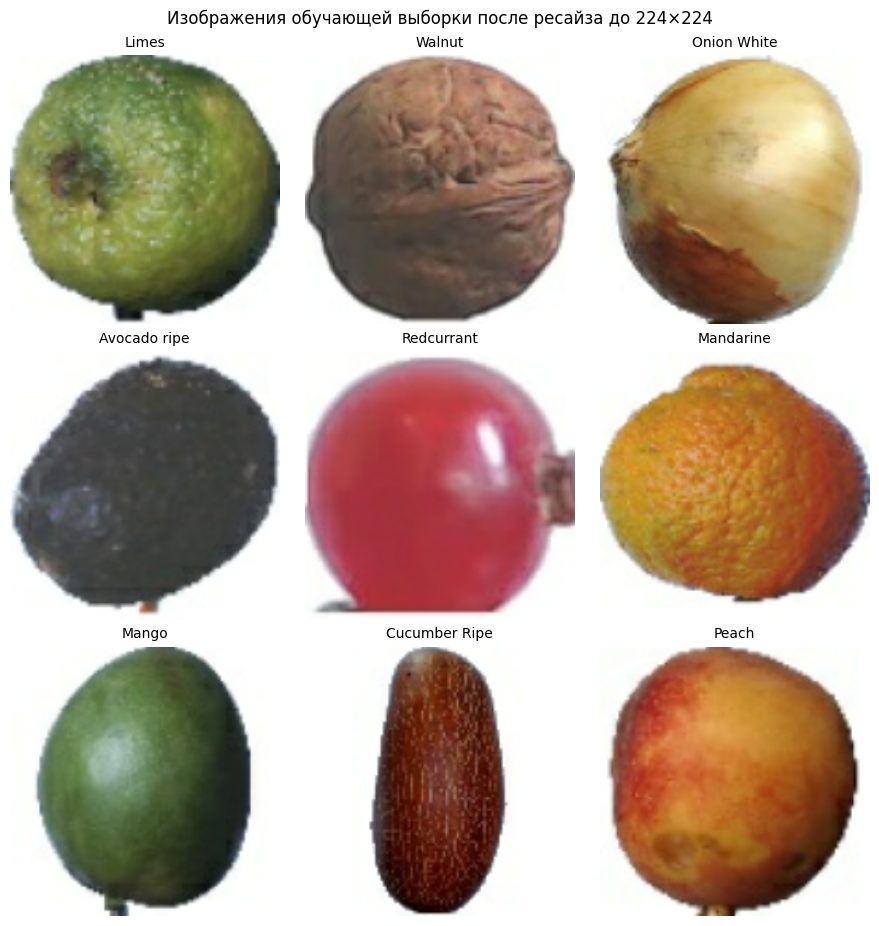

In [5]:
# Первые 9 изображений из обучающей выборки после ресайза до 224×224
plt.figure(figsize=(9, 9.4))
for images, labels in train_raw.take(1).map(resize_to_vgg):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]], fontsize=10)
        plt.axis("off")
plt.suptitle(f"Изображения обучающей выборки после ресайза до {IMG_HEIGHT}×{IMG_WIDTH}")
plt.tight_layout()
plt.show()

### 5.6. Оптимизация конвейера данных

Наборы кэшируются в памяти (`cache`), обучающий набор перемешивается (`shuffle`), а следующий батч готовится, пока обрабатывается текущий (`prefetch`). Две особенности по сравнению с работой № 9:
- **Ресайз после кэша.** В кэше хранятся изображения 100×100 в `uint8` (пиксели — целые 0..255, так что потерь нет), а до 224×224 они увеличиваются на лету при каждом проходе. Кэш уже увеличенных изображений даже в `uint8` занял бы около 12,7 ГБ — всю оперативную память Colab, — а во float32 — около 51 ГБ. Ресайз нагружает только процессор и идёт параллельно с вычислениями на GPU.
- **Порядок операций:** `shuffle` стоит до ресайза. В буфере перемешивания 1000 батчей; в размере 224×224 во float32 они заняли бы около 18 ГБ, а в исходном виде занимают меньше 1 ГБ.

Нормализацию здесь не выполняем: предобработка VGG16 (перестановка каналов и вычитание средних ImageNet) встроена в модель (раздел 6.2), и конвейер подаёт обычные RGB-изображения со значениями 0..255.

In [6]:
AUTOTUNE = tf.data.AUTOTUNE


def to_uint8(images, labels):
    # Пиксели — целые 0..255, поэтому переход к uint8 без потерь, а кэш в 4 раза меньше
    return tf.cast(images, tf.uint8), labels


# Кэш хранит изображения 100×100 в uint8; ресайз до 224×224 выполняется после кэша, на лету.
# shuffle стоит до ресайза: буфер из 1000 батчей 224×224 во float32 занял бы около 18 ГБ
train_cached = train_raw.map(to_uint8, num_parallel_calls=AUTOTUNE).cache()
val_cached = val_raw.map(to_uint8, num_parallel_calls=AUTOTUNE).cache()
test_cached = test_raw.map(to_uint8, num_parallel_calls=AUTOTUNE).cache()

train_ds = train_cached.shuffle(1000, seed=SEED).map(resize_to_vgg, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_cached.map(resize_to_vgg, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_cached.map(resize_to_vgg, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Объём кэша всех трёх выборок в разных вариантах хранения
n_images = len(train_raw.file_paths) + len(val_raw.file_paths) + len(test_raw.file_paths)
for title, side, bytes_per_value in [("100×100, uint8 (используется)", 100, 1),
                                     ("224×224, uint8", 224, 1),
                                     ("224×224, float32", 224, 4)]:
    print(f"Кэш {title}: {n_images * side * side * 3 * bytes_per_value / 2**30:.1f} ГБ")

Кэш 100×100, uint8 (используется): 2.5 ГБ
Кэш 224×224, uint8: 12.7 ГБ
Кэш 224×224, float32: 50.7 ГБ


## 6. Построение моделей (задание 3)

По структуре отчёта строятся два варианта VGG16: «с нуля» (шаг 7a методических указаний) — только для сравнения числа параметров, и с Transfer Learning (шаг 7b, задание 3) — основная модель работы.

### 6.1. VGG16 «с нуля» (для сравнения)

In [7]:
# Шаг 7a методических указаний: архитектура VGG16 без предобученных весов (weights=None)
# и классификатор Flatten → Dense(512) → Dropout(0.5) → Dense(131).
# Модель только строится и не обучается (см. текст ниже)
base_scratch = VGG16(include_top=False, weights=None, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))

model_scratch = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    base_scratch,
    layers.Flatten(),                          # 7×7×512 → 25 088
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32"),
], name="vgg16_scratch")

model_scratch.summary()

# Модель дальше не нужна — освобождаем память
del model_scratch, base_scratch

Model: "vgg16_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 131)            │        67,203 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,627,459 (105.39 MB)

 Trainable params: 27,627,459 (105.39 MB)

 Non-trainable params: 0 (0.00 B)

Все 27,6 млн параметров этого варианта обучаемые, из них 12,8 млн — в слое Dense(512) после `Flatten`. Чтобы обучить его, градиенты нужно считать через все 13 свёрточных слоёв: эпоха шла бы примерно втрое дольше, чем при Transfer Learning, а эпох понадобилось бы 30–50 (шаг 9 методических указаний) — это несколько часов работы GPU T4, и при 54 тысячах почти одинаковых кадров такая большая сеть склонна к переобучению. Обязательные задания обучения с нуля не требуют, поэтому дальше используется Transfer Learning.

### 6.2. VGG16 с Transfer Learning

Модель построена по заданию 3: свёрточная часть VGG16 с весами ImageNet (`include_top=False`) заморожена, поверх — классификатор GlobalAveragePooling2D → Dense(512, ReLU) → Dropout(0,5) → Dense(131, softmax). Отличия от шаблона методических указаний:

| | Шаблон (шаг 7b) | Модель этой работы |
|---|---|---|
| Предобработка входа | нет | **`vgg16_preprocess`** — стандартная `preprocess_input` внутри модели |
| Выходной слой | Dense(131, softmax) | Dense(131, softmax) с `dtype='float32'` — требование mixed precision (раздел 3.6) |

Зачем это сделано:
- **Предобработка внутри модели.** Без `preprocess_input` веса ImageNet получают вход в «чужом» формате (раздел 3.4). Встроенная в модель предобработка сохраняется вместе с ней, поэтому при инференсе (разделы 9 и 11) на вход подаётся обычное изображение RGB 0..255 и этот шаг невозможно забыть.
- **Почему мини-модель, а не `Lambda`.** Проверено в Keras 3.15: модель со слоем `Lambda(preprocess_input)` сохраняется в `.keras`, но при загрузке Keras не находит функцию и выдаёт ошибку. Вызов `preprocess_input` на символическом входе превращается в стандартные операции Keras (перестановка каналов и сложение), которые сохраняются и загружаются штатно. Они обёрнуты в маленькую модель `vgg16_preprocess`, чтобы в summary занимать одну строку.

In [8]:
# Свёрточная часть VGG16 с весами ImageNet, без классификатора на 1000 классов
base_vgg = VGG16(include_top=False, weights="imagenet", input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
base_vgg.trainable = False       # замораживаем все 13 свёрточных слоёв

# Предобработка VGG16 как часть модели: RGB → BGR и вычитание среднего пикселя ImageNet (раздел 3.4)
pre_input = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
vgg_preprocess = models.Model(pre_input, preprocess_input(pre_input), name="vgg16_preprocess")

model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),   # изображение RGB, значения 0..255
    vgg_preprocess,                                   # вход в формате, на котором обучалась VGG16
    base_vgg,                                         # замороженный экстрактор признаков: → 7×7×512
    layers.GlobalAveragePooling2D(),                  # 7×7×512 → 512 (раздел 3.5)
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32"),  # softmax во float32 (раздел 3.6)
], name="fruits360_vgg16")

# Вывод архитектуры
model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "fruits360_vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16_preprocess (Functional)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 131)            │        67,203 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,044,547 (57.39 MB)

 Trainable params: 329,859 (1.26 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Из 15,04 млн параметров обучаются только **329 859** (2,2 %) — веса нового классификатора: 262 656 у Dense(512) и 67 203 у выходного слоя. 14,71 млн весов VGG16 заморожены (`Non-trainable params`). Действие встроенной предобработки на одном батче:

In [9]:
# Каналы переставлены (RGB → BGR) и сдвинуты на средние ImageNet; результат совпадает с preprocess_input
sample, _ = next(iter(train_raw.take(1).map(resize_to_vgg)))
processed = vgg_preprocess(sample).numpy()
print("Средние по каналам до предобработки    (R, G, B):", np.round(sample.numpy().mean(axis=(0, 1, 2)), 1))
print("Средние по каналам после предобработки (B, G, R):", np.round(processed.mean(axis=(0, 1, 2)), 1))
print("Совпадает с preprocess_input:", np.allclose(processed, preprocess_input(sample.numpy().copy())))

Средние по каналам до предобработки    (R, G, B): [175.6 149.  125.3]
Средние по каналам после предобработки (B, G, R): [21.  31.9 51.4]
Совпадает с preprocess_input: True


### 6.3. Активации слоёв block1_conv1 и block5_conv3 (задание 10*)

Свёрточная часть заморожена, поэтому её активации не зависят от обучения классификатора: это признаки, которые VGG16 выучила на ImageNet. Для одного тестового изображения (клубника) строятся выходы первого свёрточного слоя `block1_conv1` (64 карты 224×224) и последнего — `block5_conv3` (512 карт 14×14). Для каждого слоя показаны 16 каналов с наибольшей средней активацией на этом изображении: у каждой карты своя шкала, чем темнее, тем сильнее отклик.

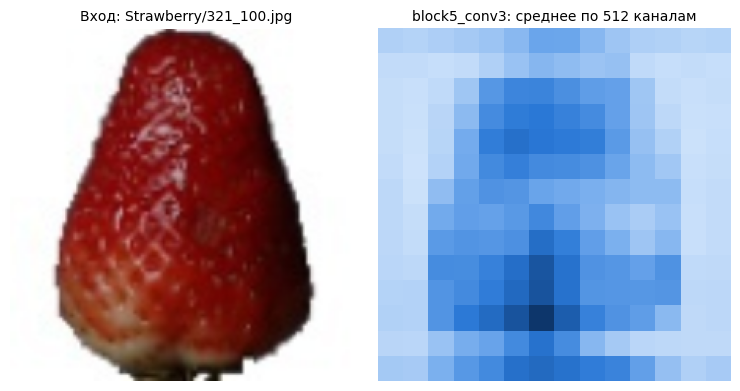

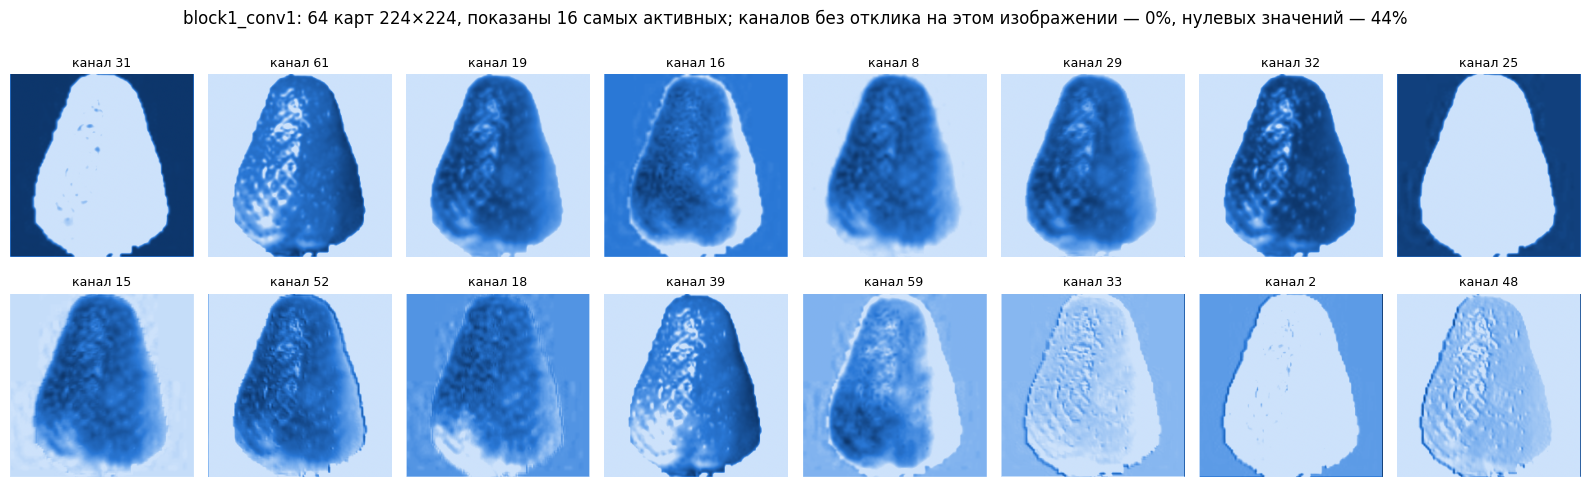

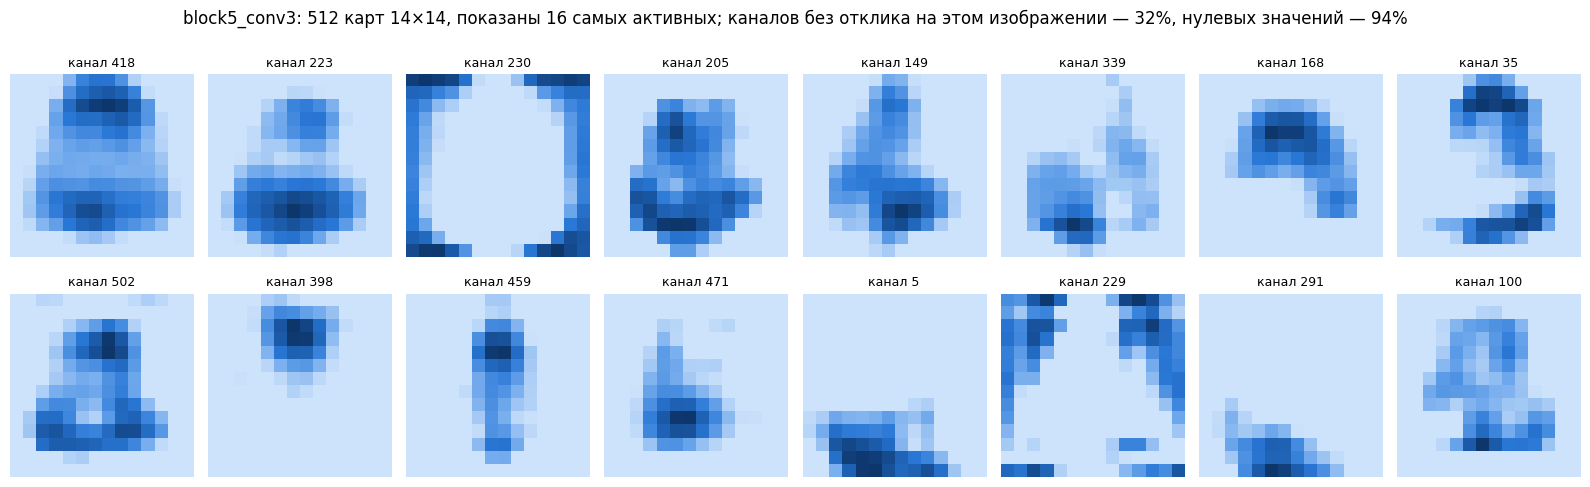

In [10]:
# Модель для чтения промежуточных выходов VGG16: первый и последний свёрточные слои
activation_model = models.Model(
    base_vgg.input,
    [base_vgg.get_layer("block1_conv1").output, base_vgg.get_layer("block5_conv3").output],
)

# Тестовое изображение, увеличенное до 224×224 так же, как в predict_image (раздел 9)
act_path = test_dir / "Strawberry" / "321_100.jpg"
act_image = tf.keras.utils.img_to_array(
    tf.keras.utils.load_img(act_path, target_size=(IMG_HEIGHT, IMG_WIDTH), interpolation="bilinear"))
act1, act5 = [np.asarray(a[0], dtype="float32") for a in activation_model(vgg_preprocess(act_image[None, ...]))]


def show_activations(act, layer_name, n=16):
    """Показывает n каналов слоя с наибольшей средней активацией на изображении."""
    top = np.argsort(act.mean(axis=(0, 1)))[::-1][:n]
    fig, axes = plt.subplots(2, n // 2, figsize=(16, 5.2))
    for ax, ch in zip(axes.flat, top):
        ax.imshow(act[:, :, ch], cmap=SEQ_CMAP)
        ax.set_title(f"канал {ch}", fontsize=9)
        ax.axis("off")
    silent = (act.max(axis=(0, 1)) == 0).mean()
    fig.suptitle(f"{layer_name}: {act.shape[2]} карт {act.shape[0]}×{act.shape[1]}, показаны 16 самых активных; "
                 f"каналов без отклика на этом изображении — {silent:.0%}, нулевых значений — {(act == 0).mean():.0%}")
    plt.tight_layout()
    plt.show()


# Исходное изображение и средняя по 512 каналам активация block5_conv3
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.9))
axes[0].imshow(act_image.astype("uint8"))
axes[0].set_title(f"Вход: {act_path.parent.name}/{act_path.name}", fontsize=10)
axes[1].imshow(act5.mean(axis=2), cmap=SEQ_CMAP)
axes[1].set_title("block5_conv3: среднее по 512 каналам", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

show_activations(act1, "block1_conv1")
show_activations(act5, "block5_conv3")

**Что видно на картах.**
- **`block1_conv1`** — простые фильтры, применённые прямо к пикселям. Карты сохраняют полное разрешение 224×224 и похожи на обработанные копии изображения: одни каналы выделяют белый фон или, наоборот, весь плод, другие — тёмные и красные области, третьи — контур плода и границы семечек. Каналов без отклика нет: цвет и перепады яркости есть почти на любом изображении.
- **`block5_conv3`** — признаки после 13 свёрток: рецептивное поле каждого нейрона — 196×196 пикселей, почти весь кадр 224×224. Карты грубые (14×14), а активность разреженная: около трети каналов на этом изображении не откликаются совсем, нулями оказываются около 94 % значений. Активные каналы реагируют на отдельные части объекта — верх с чашечкой, низ, середину плода — или на его границу с фоном, а средняя карта показывает, что сеть «смотрит» на плод, а не на фон.

Это иллюстрирует идею Transfer Learning из раздела 3.4: первые слои дают универсальные признаки, полезные для любых изображений, а последний блок — сложные и специфичные для ImageNet. Поэтому при fine-tuning (раздел 12.1) имеет смысл размораживать именно блок 5.

## 7. Обучение модели (задание 4)

Параметры обучения — по заданию:
- оптимизатор **Adam** с шагом $10^{-3}$, функция потерь `sparse_categorical_crossentropy`, метрика accuracy;
- до **15 эпох**, размер батча 32;
- **EarlyStopping**: `monitor='val_loss'`, `patience=5`, `restore_best_weights=True`. Обучение останавливается, если потери на валидации не улучшаются 5 эпох подряд, и модель получает веса лучшей эпохи (в Keras 3 это происходит и тогда, когда остановки не было);
- **смешанная точность** `mixed_float16` (раздел 3.6): при компиляции Keras сам оборачивает Adam в `LossScaleOptimizer`, который масштабирует потери;
- **время обучения** замеряется функцией `time.time()` до и после `model.fit()` и выводится в секундах и минутах (обязательное требование).

Обучаются только 329 859 весов классификатора, но каждое изображение на каждой эпохе проходит через всю свёрточную часть VGG16 (около 15,3 млрд умножений-сложений), поэтому эпоха длится заметно дольше, чем у CNN из работы № 9.

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),  # при mixed_float16 Keras добавит масштабирование потерь
    loss="sparse_categorical_crossentropy",                  # метки — целые номера классов
    metrics=["accuracy"],
)
print("Оптимизатор:", type(model.optimizer).__name__)

Оптимизатор: LossScaleOptimizer


In [12]:
EPOCHS = 15

# Ранняя остановка, чтобы избежать переобучения
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

# Замер времени обучения (обязательное требование)
print("Начало обучения...")
start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop],
    verbose=1,
)

end_time = time.time()
training_time = end_time - start_time

epochs_run = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nОбучение завершено за {training_time:.2f} секунд ({training_time / 60:.2f} минут)")
print(f"Эпох выполнено: {epochs_run} из {EPOCHS}, в среднем {training_time / epochs_run:.1f} с на эпоху")
print(f"Лучшая эпоха по val_loss: {best_epoch}")

Начало обучения...
Epoch 1/15
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 133s 68ms/step - accuracy: 0.9066 - loss: 0.4152 - val_accuracy: 0.9956 - val_loss: 0.0140
Epoch 2/15
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 112s 66ms/step - accuracy: 0.9777 - loss: 0.0681 - val_accuracy: 0.9984 - val_loss: 0.0048
Epoch 3/15
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 114s 67ms/step - accuracy: 0.9826 - loss: 0.0579 - val_accuracy: 0.9995 - val_loss: 0.0014
Epoch 4/15
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 114s 67ms/step - accuracy: 0.9832 - loss: 0.0634 - val_accuracy: 0.9989 - val_loss: 0.0036
Epoch 5/15
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 115s 68ms/step - accuracy: 0.9866 - loss: 0.0531 - val_accuracy: 0.9996 - val_loss: 7.9556e-04
Epoch 6/15
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 114s 67ms/step - accuracy: 0.9873 - loss: 0.0542 - val_accuracy: 0.9999 - val_loss: 6.4892e-04
Epoch 7/15
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 114s 68ms/step - accuracy: 0.9886 - loss: 0.0514 - val_accuracy: 0.9996 - val_loss: 8.4224e-04
Epoch 8/15
1693/1693 ━━━━━━━━━━━━━━━━━

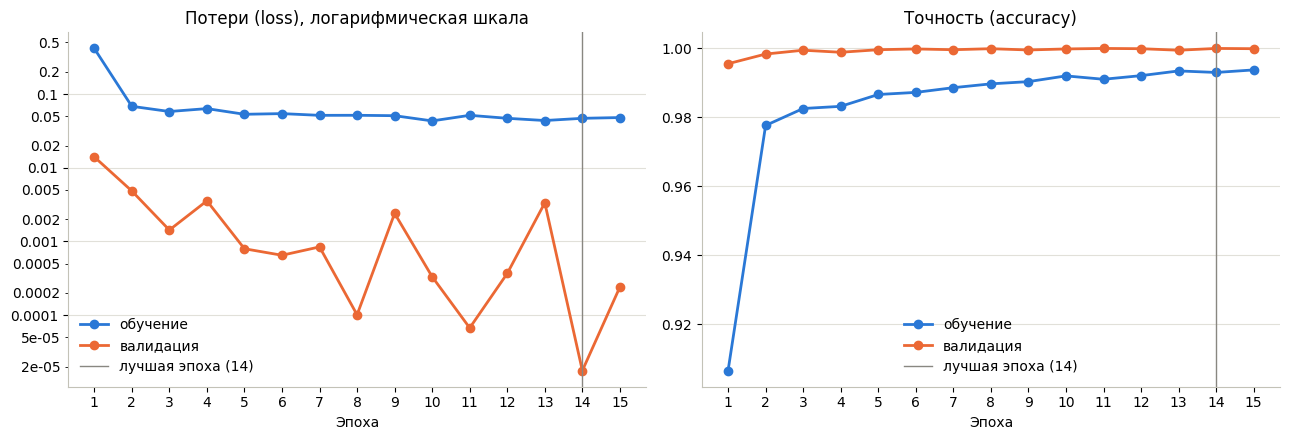

In [13]:
def plot_history(hist, best_epoch, finetune_from=None):
    """Графики потерь (логарифмическая шкала) и точности на обучающей и валидационной выборках."""
    epochs_range = np.arange(1, len(hist["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    panels = [("loss", "Потери (loss), логарифмическая шкала"), ("accuracy", "Точность (accuracy)")]

    for ax, (metric, title) in zip(axes, panels):
        ax.plot(epochs_range, hist[metric], color=C_BLUE, lw=2, marker="o", ms=6, label="обучение")
        ax.plot(epochs_range, hist[f"val_{metric}"], color=C_ORANGE, lw=2, marker="o", ms=6, label="валидация")
        ax.axvline(best_epoch, color=C_MUTED, lw=1, label=f"лучшая эпоха ({best_epoch})")
        if finetune_from is not None:
            ax.axvline(finetune_from - 0.5, color=C_MUTED, lw=1, ls="--", label="начало fine-tuning")
        ax.set(title=title, xlabel="Эпоха", xticks=epochs_range)
        ax.grid(axis="y")
        ax.legend()

    # Логарифмическая шкала потерь с обычными подписями: 0.01, 0.02, 0.05, 0.1, ...
    plain = FuncFormatter(lambda v, _: f"{v:g}")
    axes[0].set_yscale("log")
    axes[0].yaxis.set_major_formatter(plain)
    axes[0].yaxis.set_minor_locator(LogLocator(subs=(2, 5)))
    axes[0].yaxis.set_minor_formatter(plain)
    plt.tight_layout()
    plt.show()


plot_history(history.history, best_epoch)

### 7.1. Анализ обучения

**Время обучения:** 1785,7 с (29,8 мин) на GPU NVIDIA T4 в Google Colab со смешанной точностью — все 15 эпох, в среднем 119 с на эпоху. Первая эпоха заняла 133 с: в ней изображения читаются с диска в кэш. Большинство остальных эпох шли по 112–115 с, а эпохи 11 и 15 — по 141–142 с; шаг обучения при этом занимал те же 67–68 мс, так что лишние ~27 с пришлись не на шаги обучения. Всего обучение длилось втрое дольше, чем у CNN из работы № 9 (584 с), хотя обучаемых параметров здесь почти в 16 раз меньше: каждое изображение на каждой эпохе проходит через всю свёрточную часть VGG16.

**Ранняя остановка не сработала.** Минимум `val_loss` обновлялся на эпохах 1, 2, 3, 5, 6, 8, 11 и 14 — ни разу не было 5 эпох подряд без улучшения, поэтому обучение прошло все 15 эпох. Лучшая — 14-я эпоха (`val_loss` = 1,8·10⁻⁵, `val_accuracy` = 100 %), её веса модель и получила.

**Что видно на графиках:**
- Классификатор поверх признаков ImageNet обучается очень быстро: после первой же эпохи `val_accuracy` = 99,56 %, с 3-й эпохи — 99,89–100 %. CNN из работы № 9 после первой эпохи давала 86 % и вышла на 99,8 % только к 6-й эпохе. Готовые признаки VGG16 почти сразу разделяют классы Fruits-360.
- Потери на обучении за две эпохи падают с 0,415 до 0,068, а с 5-й эпохи стоят на уровне 0,043–0,054; точность на обучении растёт медленно (98,7 → 99,4 %). Это плато маленького классификатора: признаки VGG16 заморожены, и улучшать можно только два слоя Dense. Fine-tuning в разделе 12.1 сдвигает это плато.
- Точность на обучении ниже валидационной, а потери выше по той же причине, что в работе № 9: метрики обучения считаются с работающим Dropout(0,5) и усредняются по эпохе, а валидация считается по итоговым весам эпохи.
- `val_loss` прыгает на два порядка — от 1,8·10⁻⁵ до 3,6·10⁻³ — при `val_accuracy` 99,9–100 %: несколько уверенных ошибок среди 13 538 изображений сильно меняют среднее, поэтому лучшая эпоха выбрана по шумному сигналу.
- Признаков переобучения (роста `val_loss` при падении `loss`) нет, но валидация, как и в работе № 9, завышает качество: 99,99–100 % на валидации против 98,39 % на тесте (раздел 8). Валидационные кадры — соседние кадры тех же видео, что и обучающие, то есть почти их дубликаты.

## 8. Оценка качества (задание 5)

Модель оценивается на отдельной тестовой выборке (папка `Test`, 22 688 изображений), которая не участвовала ни в обучении, ни в ранней остановке. Считаем accuracy и loss, затем строим classification report (precision, recall, F1 по каждому классу) и матрицу ошибок и разбираем самые частые ошибки.

In [14]:
# Оценка на тестовом наборе
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Тестовая точность (accuracy): {test_acc:.4f}")
print(f"Тестовые потери (loss): {test_loss:.4f}")

Тестовая точность (accuracy): 0.9839
Тестовые потери (loss): 0.2279


In [15]:
# Истинные метки и предсказания (тестовая выборка не перемешивается, поэтому порядок совпадает)
y_true = np.concatenate([labels.numpy() for _, labels in test_cached])
start = time.time()
vgg_probs = model.predict(test_ds, verbose=0)
vgg_predict_time = time.time() - start
y_pred = vgg_probs.argmax(axis=1)
all_labels = np.arange(NUM_CLASSES)

print(f"Предсказание для {len(y_true)} изображений: {vgg_predict_time:.1f} с "
      f"({len(y_true) / vgg_predict_time:.0f} изображений/с)\n")
print(classification_report(y_true, y_pred, labels=all_labels, target_names=class_names, digits=3, zero_division=0))

Предсказание для 22688 изображений: 39.3 с (577 изображений/с)

                     precision    recall  f1-score   support

     Apple Braeburn      0.932     1.000     0.965       164
 Apple Crimson Snow      0.831     1.000     0.908       148
     Apple Golden 1      1.000     1.000     1.000       160
     Apple Golden 2      1.000     1.000     1.000       164
     Apple Golden 3      0.988     1.000     0.994       161
 Apple Granny Smith      1.000     1.000     1.000       164
    Apple Pink Lady      1.000     1.000     1.000       152
        Apple Red 1      1.000     0.988     0.994       164
        Apple Red 2      0.988     1.000     0.994       164
        Apple Red 3      1.000     1.000     1.000       144
Apple Red Delicious      1.000     1.000     1.000       166
 Apple Red Yellow 1      0.994     1.000     0.997       164
 Apple Red Yellow 2      1.000     1.000     1.000       219
            Apricot      1.000     1.000     1.000       164
            Avocado 

In [16]:
# 10 классов с наименьшим F1-score
report = classification_report(y_true, y_pred, labels=all_labels, target_names=class_names,
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[class_names, ["precision", "recall", "f1-score", "support"]]
per_class["support"] = per_class["support"].astype(int)
per_class.sort_values("f1-score").head(10).round(3)

,precision,recall,f1-score,support
Nectarine Flat,1.000,0.669,0.801,160
Beetroot,0.799,0.873,0.834,150
Corn Husk,1.000,0.721,0.838,154
Eggplant,1.000,0.731,0.844,156
Pear 2,1.000,0.750,0.857,232
Cherry Rainier,0.774,1.000,0.872,246
Mango Red,0.991,0.796,0.883,142
Tomato Heart,1.000,0.820,0.901,228
Kohlrabi,0.822,1.000,0.902,157
Apple Crimson Snow,0.831,1.000,0.908,148


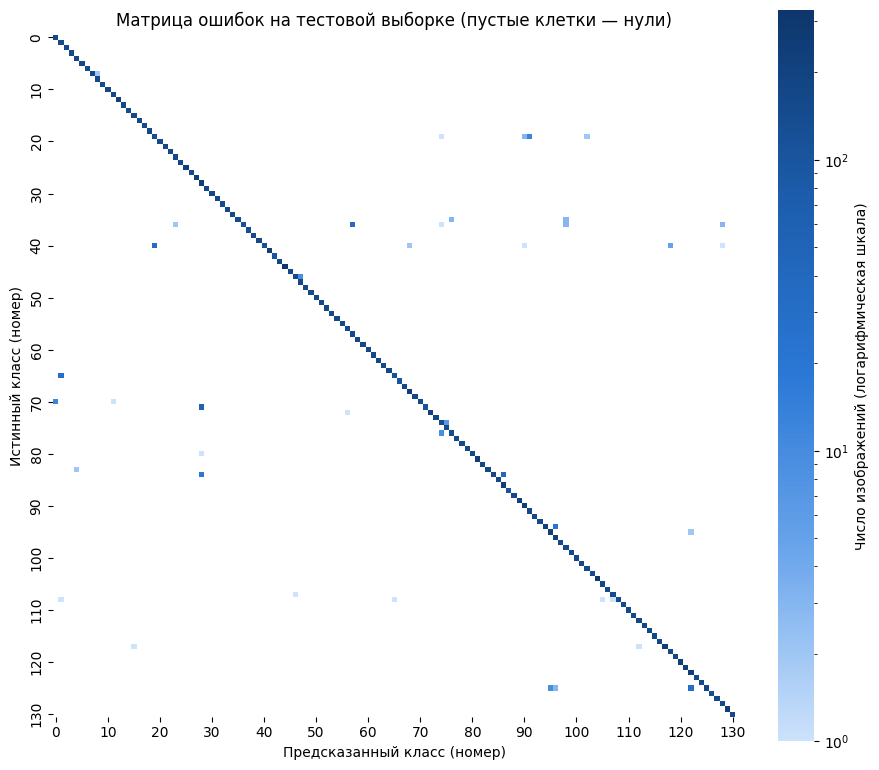

In [17]:
# Полная матрица ошибок 131×131. Шкала цвета логарифмическая, иначе редкие ошибки
# не видны рядом с диагональю; нулевые клетки не закрашены
cm = confusion_matrix(y_true, y_pred, labels=all_labels)

fig, ax = plt.subplots(figsize=(11, 9.5))
sns.heatmap(cm, mask=(cm == 0), cmap=SEQ_CMAP, norm=LogNorm(vmin=1, vmax=cm.max()), square=True,
            xticklabels=10, yticklabels=10, cbar_kws={"label": "Число изображений (логарифмическая шкала)"}, ax=ax)
ax.set(title="Матрица ошибок на тестовой выборке (пустые клетки — нули)",
       xlabel="Предсказанный класс (номер)", ylabel="Истинный класс (номер)")
plt.show()

In [18]:
# Самые частые ошибки — наибольшие внедиагональные элементы матрицы ошибок
errors = cm.copy()
np.fill_diagonal(errors, 0)
print(f"Ошибок на тесте: {errors.sum()} из {cm.sum()} ({errors.sum() / cm.sum():.2%})")

true_idx, pred_idx = np.nonzero(errors)
top = np.argsort(-errors[true_idx, pred_idx], kind="stable")[:10]
top_true, top_pred = true_idx[top], pred_idx[top]

top_pairs = pd.DataFrame({
    "Истинный класс": [class_names[i] for i in top_true],
    "Предсказанный класс": [class_names[j] for j in top_pred],
    "Ошибок": errors[top_true, top_pred],
    "% изображений класса": (100 * errors[top_true, top_pred] / cm[top_true].sum(axis=1)).round(1),
})
top_pairs

Ошибок на тесте: 366 из 22688 (1.61%)


,Истинный класс,Предсказанный класс,Ошибок,% изображений класса
0,Nectarine Flat,Cherry Rainier,53,33.1
1,Pear 2,Pear Forelle,40,17.2
2,Corn Husk,Kohlrabi,34,22.1
3,Eggplant,Beetroot,33,21.2
4,Mango Red,Apple Crimson Snow,29,20.4
5,Tomato Heart,Tomato 3,29,12.7
6,Pepper Orange,Pepper Yellow,22,9.4
7,Pear 2,Cherry Rainier,18,7.8
8,Beetroot,Pear Williams,13,8.7
9,Nectarine,Apple Braeburn,12,7.3


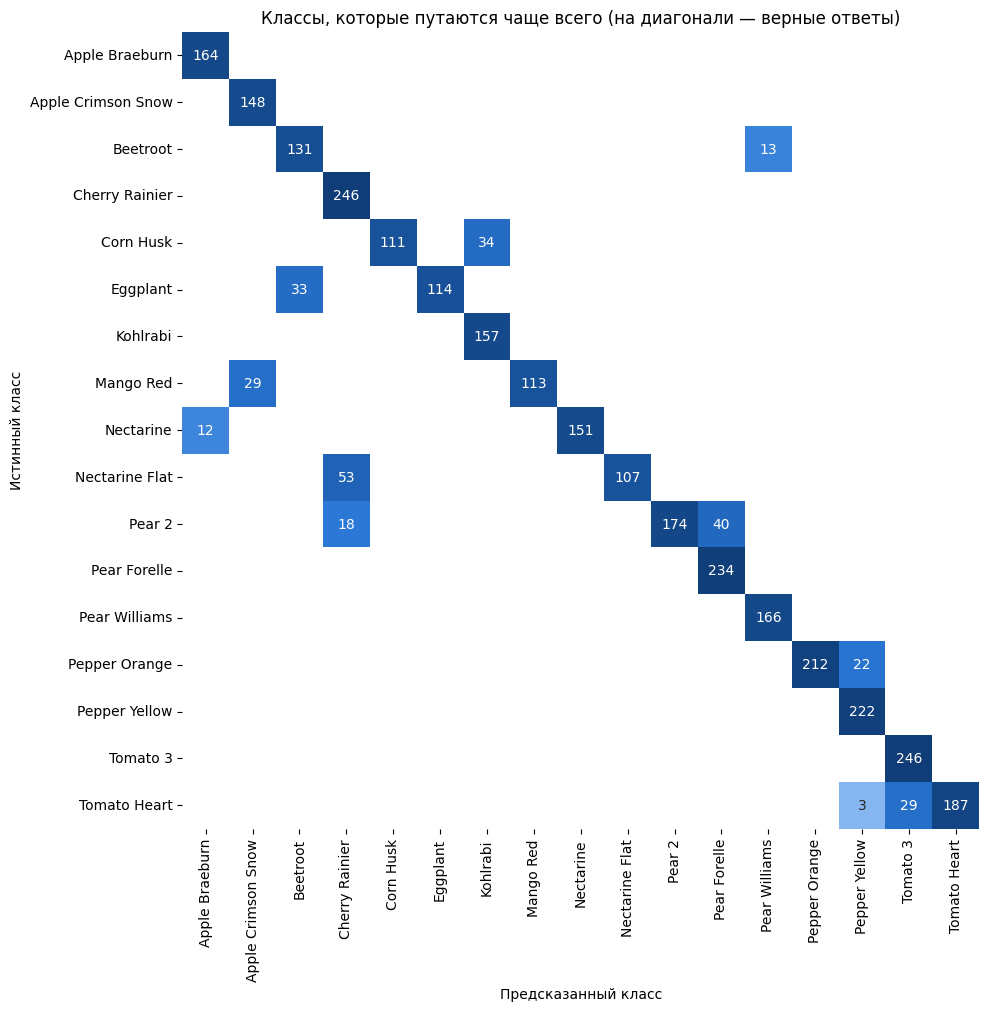

In [19]:
# Увеличенный фрагмент матрицы ошибок: только классы из 10 самых частых путаниц
focus = sorted(set(top_true) | set(top_pred))
sub_cm = cm[np.ix_(focus, focus)]
focus_names = [class_names[i] for i in focus]

fig, ax = plt.subplots(figsize=(1.5 + 0.6 * len(focus), 1 + 0.55 * len(focus)))
sns.heatmap(sub_cm, mask=(sub_cm == 0), annot=True, fmt="d", cmap=SEQ_CMAP, norm=LogNorm(vmin=1, vmax=cm.max()),
            square=True, cbar=False, xticklabels=focus_names, yticklabels=focus_names, ax=ax)
ax.set(title="Классы, которые путаются чаще всего (на диагонали — верные ответы)",
       xlabel="Предсказанный класс", ylabel="Истинный класс")
plt.show()

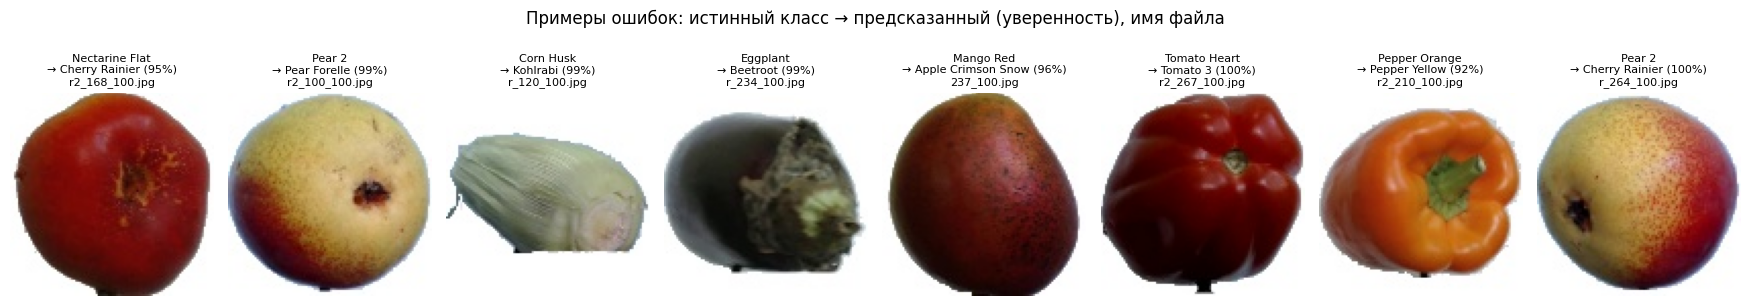

In [20]:
# По одному ошибочно классифицированному изображению для 8 самых частых пар «истинный → предсказанный»
test_files = np.array(test_raw.file_paths)
pairs = list(zip(top_true, top_pred))[:8]

fig, axes = plt.subplots(1, len(pairs), figsize=(2.2 * len(pairs), 3.5), squeeze=False)
for ax, (t, p) in zip(axes[0], pairs):
    idx = np.flatnonzero((y_true == t) & (y_pred == p))[0]
    ax.imshow(tf.keras.utils.load_img(test_files[idx]))
    ax.set_title(f"{class_names[t]}\n→ {class_names[p]} ({vgg_probs[idx, p]:.0%})\n{os.path.basename(test_files[idx])}",
                 fontsize=8)
    ax.axis("off")
fig.suptitle("Примеры ошибок: истинный класс → предсказанный (уверенность), имя файла")
plt.tight_layout()
plt.show()

### 8.1. Анализ ошибок

**Общее качество.** Accuracy на тесте — **98,39 %** (366 ошибок из 22 688 изображений), loss — 0,2279. Macro-усреднённые precision / recall / F1 — 0,987 / 0,984 / 0,984, weighted — 0,986 / 0,984 / 0,984. Это хуже, чем у CNN из работы № 9 (99,17 %, 189 ошибок; сравнение — в разделе 12.2). У 110 из 131 класса нет ни одной ошибки, а у 86 классов precision и recall равны 1,000 — среди них и близкие сорта: Apple Golden 1/2, Cherry 1/2, Grape White 3/4, Tomato 1/2/4 и все три сорта бананов.

**Почему потери на тесте высокие при точности 98 %.** VGG16 ошибается уверенно: у 84 % ошибочных ответов вероятность выше 0,9, медиана — 0,999 (подсчёт по предсказаниям сохранённой модели). Верные ответы дают почти нулевые потери, поэтому test loss на 99,5 % складывается из потерь на 1,6 % ошибочных изображений.

**Ошибки сосредоточены в нескольких классах.** Все ошибки приходятся на 21 истинный класс, а 10 самых частых пар дают 283 из 366 (77 %). Сильнее всего падает recall у Nectarine Flat (0,669), Corn Husk (0,721), Eggplant (0,731), Pear 2 (0,750), Mango Red (0,796) и Tomato Heart (0,820). Ошибки однонаправленные: изображения этих классов «оседают» в классах-двойниках с пониженной precision — Cherry Rainier (0,774), Beetroot (0,799), Kohlrabi (0,822), Apple Crimson Snow (0,831), Pear Forelle (0,854), Tomato 3 (0,888), — а обратных ошибок нет (фрагмент матрицы ошибок).

**Почему путаются именно эти пары.** Как и у CNN в работе № 9, ошибки — длинные серии соседних кадров, то есть определённые участки вращения плода, но пары другие. VGG16 путает плоды близкой окраски, когда характерная форма на кадре не видна:
- **Nectarine Flat → Cherry Rainier (53 ошибки, 33 % класса):** плоский нектарин со стороны плодоножки — округлый красно-жёлтый плод, а у черешни Rainier такая же двухцветная окраска; кадры `r_0`…`r_28` и `r2_168`…`r2_192`;
- **Pear 2 → Pear Forelle (40) и Cherry Rainier (18):** жёлтая груша с красным румянцем, снятая с торца, где не видно грушевидного силуэта; сплошной участок вращения `r_243`…`r_281` (сначала Pear Forelle, затем Cherry Rainier) и серия `r2_100`…`r2_118`;
- **Corn Husk → Kohlrabi (34):** очищенный бледно-зелёный початок по цвету и фактуре похож на кольраби; серия `r_133`…`r_154`;
- **Eggplant → Beetroot (33):** баклажан со стороны зелёно-коричневой чашечки похож на свёклу с остатками ботвы — 29 кадров подряд, `r_234`…`r_262`;
- **Mango Red → Apple Crimson Snow (29):** красно-зелёное манго в этих ракурсах выглядит как красное яблоко; кадры `237`…`266`;
- **Tomato Heart → Tomato 3 (29), Pepper Orange → Pepper Yellow (22):** соседние сорта одного овоща, которые различаются оттенком и рёбрами.

**Вывод.** Замороженные признаки ImageNet хорошо передают цвет и общую форму, но хуже — мелкие различия сортов, которые CNN из работы № 9 выучила прямо на этих данных: VGG16 путает между собой красно-жёлтые, бледно-зелёные и красные плоды. Fine-tuning верхнего блока (раздел 12.1) исправляет большую часть таких ошибок.

## 9. Функция предсказания (задание 6)

`predict_image(img_path)` принимает путь к изображению и возвращает пару «класс, уверенность»:
1. `load_img` загружает файл и приводит его к размеру 224×224. Интерполяция указана явно — `bilinear`, как в `image_dataset_from_directory` при обучении: по умолчанию `load_img` использует `nearest`. Проверка на 200 изображениях: с `nearest` пиксели отличаются от обучающего конвейера в среднем на 2,9 уровня яркости из 255, с `bilinear` — на 1,2, и этот остаток даёт уже не ресайз, а разные JPEG-декодеры (PIL в `load_img`, TensorFlow в `image_dataset_from_directory`);
2. `img_to_array` превращает изображение в массив 224×224×3 со значениями 0..255;
3. `expand_dims` добавляет размерность батча: модель ждёт вход формы (N, 224, 224, 3);
4. модель возвращает 131 вероятность; класс — `argmax`, уверенность — максимальная вероятность.

Отдельная предобработка не нужна: её выполняет слой `vgg16_preprocess` внутри модели. Функция проверяется на тех же 5 тестовых изображениях, что и в работе № 9 (тот же seed выбора). Столбец «Прогноз в разделе 8» — ответ модели для того же файла на тестовом конвейере: совпадение подтверждает, что `predict_image` готовит изображение так же, как при обучении.

In [21]:
def predict_image(img_path):
    """
    Загружает изображение, подготавливает его и возвращает предсказанный класс и уверенность.
    """
    # Билинейная интерполяция, как в image_dataset_from_directory (у load_img по умолчанию — nearest)
    img = tf.keras.utils.load_img(img_path, target_size=(IMG_HEIGHT, IMG_WIDTH), interpolation="bilinear")
    img_array = tf.keras.utils.img_to_array(img)   # массив 224×224×3, значения 0..255
    img_array = tf.expand_dims(img_array, 0)       # добавляем размерность батча
    predictions = model.predict(img_array, verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = float(np.max(predictions[0]))
    return predicted_class, confidence

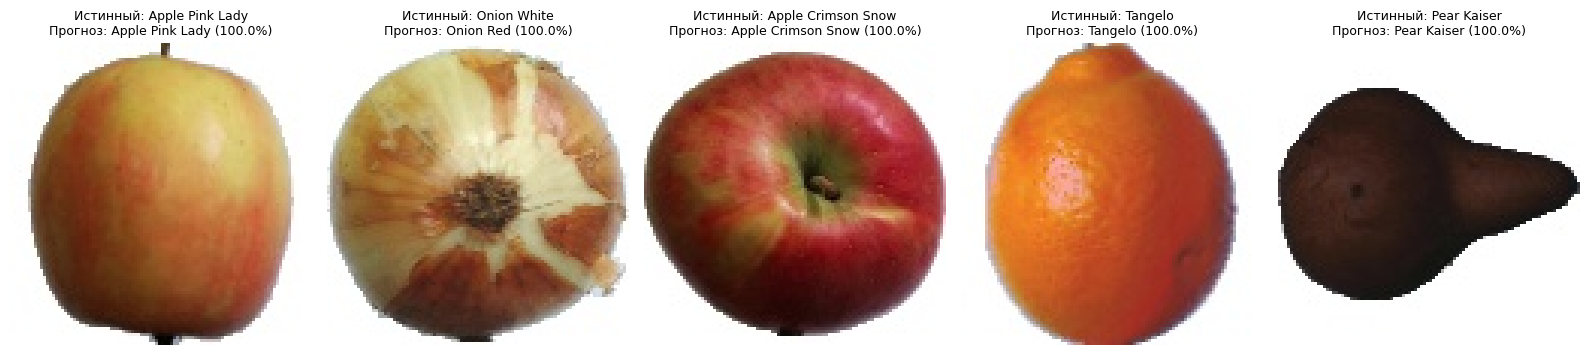

,Файл,Истинный класс,Предсказанный класс,Уверенность,Прогноз в разделе 8
0,Apple Pink Lady/253_100.jpg,Apple Pink Lady,Apple Pink Lady,1.000000,Apple Pink Lady
1,Onion White/r2_0_100.jpg,Onion White,Onion Red,0.999999,Onion Red
2,Apple Crimson Snow/r_42_100.jpg,Apple Crimson Snow,Apple Crimson Snow,1.000000,Apple Crimson Snow
3,Tangelo/91_100.jpg,Tangelo,Tangelo,1.000000,Tangelo
4,Pear Kaiser/r_7_100.jpg,Pear Kaiser,Pear Kaiser,1.000000,Pear Kaiser


In [22]:
# 5 случайных изображений разных классов из тестовой выборки (seed фиксирован — набор воспроизводим)
rng = np.random.default_rng(SEED)
sample_paths = []
for cls in rng.choice(class_names, size=5, replace=False):
    files = sorted((test_dir / cls).glob("*.jpg"))
    sample_paths.append(files[rng.integers(len(files))])

# Номер файла в тестовой выборке — чтобы сравнить с предсказаниями раздела 8
file_index = {os.path.normpath(p): i for i, p in enumerate(test_raw.file_paths)}

rows = []
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, path in zip(axes, sample_paths):
    predicted, conf = predict_image(path)
    true_class = path.parent.name
    rows.append({"Файл": f"{true_class}/{path.name}", "Истинный класс": true_class,
                 "Предсказанный класс": predicted, "Уверенность": conf,
                 "Прогноз в разделе 8": class_names[y_pred[file_index[os.path.normpath(path)]]]})
    ax.imshow(tf.keras.utils.load_img(path))
    ax.set_title(f"Истинный: {true_class}\nПрогноз: {predicted} ({conf:.1%})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

task6_results = pd.DataFrame(rows)
task6_results

Четыре изображения из пяти распознаны верно с уверенностью 100 %. Ошибка — `Onion White/r2_0_100.jpg`: белая луковица снята со стороны донца, где видны коричневатые сухие чешуи, и модель с вероятностью 0,999999 отвечает Onion Red. Это начало одной из серий ошибок раздела 8 (Onion White → Onion Red, кадры `r2_0`…`r2_13`); CNN из работы № 9 этот кадр распознала верно. Для всех пяти файлов ответ `predict_image` совпал с ответом на тестовом конвейере (столбец «Прогноз в разделе 8»), то есть функция готовит изображение так же, как при обучении.

## 10. Сохранение модели и вспомогательных объектов (задание 7)

Сохраняются два файла:
- `fruits360_vgg16_model.keras` — модель в рекомендуемом формате Keras 3: zip-архив с архитектурой, весами и состоянием оптимизатора. Встроенная предобработка и политика смешанной точности сохраняются вместе с моделью, поэтому при загрузке ничего дополнительно определять не нужно. Почти весь объём файла — замороженные веса VGG16: 14,7 млн чисел float32, около 56 МБ;
- `class_names_vgg.txt` — названия классов по одному на строку в порядке выходов модели: строка *i* соответствует выходу *i*.

In [23]:
MODEL_FILE = "fruits360_vgg16_model.keras"
CLASSES_FILE = "class_names_vgg.txt"

# Сохраняем модель в формате .keras (архитектура, веса и состояние оптимизатора в одном файле)
model.save(MODEL_FILE)
print(f"Модель сохранена в {MODEL_FILE}")

# Сохраняем список классов в текстовый файл
with open(CLASSES_FILE, "w", encoding="utf-8") as f:
    for name in class_names:
        f.write(name + "\n")
print(f"Список классов сохранён в {CLASSES_FILE}")

for name in (MODEL_FILE, CLASSES_FILE):
    print(f"  {name}: {os.path.getsize(name) / 2**20:.2f} МБ")

Модель сохранена в fruits360_vgg16_model.keras
Список классов сохранён в class_names_vgg.txt
  fruits360_vgg16_model.keras: 62.53 МБ
  class_names_vgg.txt: 0.00 МБ


In [24]:
# В Colab скачиваем файлы на компьютер, чтобы загрузить их в репозиторий
try:
    from google.colab import files
    files.download(MODEL_FILE)
    files.download(CLASSES_FILE)
except ImportError:
    print(f"Ноутбук запущен не в Colab: файлы лежат в папке {os.getcwd()}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 10.1. Загрузка файлов в репозиторий

Модель весит 62,5 МБ, а через веб-интерфейс GitHub можно загрузить файл не больше 25 МБ. Поэтому `fruits360_vgg16_model.keras` и `class_names_vgg.txt` добавлены в корень репозитория https://github.com/Danil20340/fruits-360-vgg через git (`git add`, `git commit`, `git push`). GitHub предупредил, что файл больше рекомендуемых 50 МБ, но принял его (жёсткий лимит — 100 МБ), так что Git LFS не понадобился. Raw-ссылки на файлы:
- модель: https://github.com/Danil20340/fruits-360-vgg/raw/main/fruits360_vgg16_model.keras
- список классов: https://github.com/Danil20340/fruits-360-vgg/raw/main/class_names_vgg.txt

> При первом запуске «Выполнить все» остановится в разделе 11 с ошибкой HTTP 404: файлов в репозитории ещё нет, это ожидаемо. Загрузите файлы и продолжите выполнение с раздела 11 в том же сеансе Colab (для сравнения нужны результаты разделов 8 и 9).

## 11. Загрузка модели из репозитория и быстрый инференс (задание 8)

Следующая ячейка не зависит от обучения: в новом сеансе достаточно выполнить только её. Файлы скачиваются по raw-ссылкам под другими именами, чтобы точно использовалась модель из репозитория, а не локальный файл из раздела 10. Вместо `!wget` из методических указаний используется `urllib.request.urlretrieve`: он работает и в Colab, и локально. Модель загружается обычным `load_model` — без `custom_objects` и `safe_mode=False`, потому что встроенная предобработка состоит из стандартных операций Keras.

In [26]:
import urllib.request

import numpy as np
import tensorflow as tf

# Raw-ссылки на файлы в репозитории
url_model = "https://github.com/Danil20340/fruits-360-vgg/raw/main/fruits360_vgg16_model.keras"
url_classes = "https://github.com/Danil20340/fruits-360-vgg/raw/main/class_names_vgg.txt"

# Скачивание файлов (аналог !wget -O)
urllib.request.urlretrieve(url_model, "repo_fruits360_vgg16_model.keras")
urllib.request.urlretrieve(url_classes, "repo_class_names_vgg.txt")

# Загрузка модели; compile=False — модель нужна только для предсказаний
loaded_model = tf.keras.models.load_model("repo_fruits360_vgg16_model.keras", compile=False)

# Загрузка списка классов
with open("repo_class_names_vgg.txt", encoding="utf-8") as f:
    loaded_class_names = [line.strip() for line in f if line.strip()]

print(f"Модель загружена. Параметров: {loaded_model.count_params()}, классов: {len(loaded_class_names)}")


# Функция предсказания с загруженной моделью
def predict_loaded_image(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224), interpolation="bilinear")
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)
    predictions = loaded_model.predict(img_array, verbose=0)
    predicted_class = loaded_class_names[np.argmax(predictions[0])]
    confidence = float(np.max(predictions[0]))
    return predicted_class, confidence

Модель загружена. Параметров: 15044547, классов: 131


In [27]:
# Предсказания загруженной модели для тех же изображений, что и в задании 6
loaded_results = [predict_loaded_image(path) for path in sample_paths]

comparison = task6_results[["Файл", "Предсказанный класс", "Уверенность"]].copy()
comparison["Класс (модель из репозитория)"] = [cls for cls, _ in loaded_results]
comparison["Уверенность (модель из репозитория)"] = [conf for _, conf in loaded_results]
comparison["Совпадает"] = (
    (comparison["Предсказанный класс"] == comparison["Класс (модель из репозитория)"])
    & np.isclose(comparison["Уверенность"], comparison["Уверенность (модель из репозитория)"], atol=1e-5)
)
display(comparison)

# Дополнительная проверка: полные векторы вероятностей обеих моделей на первом тестовом батче
batch_images, _ = next(iter(test_ds))
max_diff = np.abs(model.predict(batch_images, verbose=0) - loaded_model.predict(batch_images, verbose=0)).max()
print(f"Максимальное расхождение вероятностей на батче из {len(batch_images)} изображений: {max_diff:.1e}")
print("Результаты совпадают" if comparison["Совпадает"].all() and max_diff < 1e-5 else "ВНИМАНИЕ: результаты различаются")

,Файл,Предсказанный класс,Уверенность,Класс (модель из репозитория),Уверенность (модель из репозитория),Совпадает
0,Apple Pink Lady/253_100.jpg,Apple Pink Lady,1.000000,Apple Pink Lady,1.000000,True
1,Onion White/r2_0_100.jpg,Onion Red,0.999999,Onion Red,0.999999,True
2,Apple Crimson Snow/r_42_100.jpg,Apple Crimson Snow,1.000000,Apple Crimson Snow,1.000000,True
3,Tangelo/91_100.jpg,Tangelo,1.000000,Tangelo,1.000000,True
4,Pear Kaiser/r_7_100.jpg,Pear Kaiser,1.000000,Pear Kaiser,1.000000,True


Максимальное расхождение вероятностей на батче из 32 изображений: 0.0e+00
Результаты совпадают


## 12. Анализ результатов и выводы (задания 9 и 10*)

### 12.1. Fine-tuning последнего свёрточного блока (задание 10*)

Когда новый классификатор обучен, можно дообучить и верхнюю часть VGG16. Размораживается только блок 5 (`block5_conv1`–`block5_conv3`, 7,08 млн весов): его признаки самые специфичные для ImageNet, а нижние блоки выделяют общие признаки — края, цвет, текстуры (раздел 6.3), — и менять их незачем. Параметры:
- дообучается копия модели из раздела 7 (`clone_model` + её веса), поэтому модель Transfer Learning, сохранённая в разделе 10, не меняется;
- Adam с шагом $10^{-5}$ — в 100 раз меньше, чем при обучении классификатора: крупные шаги разрушили бы предобученные признаки;
- до 5 эпох, EarlyStopping с `patience=2` и `restore_best_weights=True`; время замеряется так же, как в разделе 7.

Эпоха fine-tuning дороже эпохи раздела 7: градиенты считаются ещё и через три свёрточных слоя блока 5.

In [28]:
# Копия обученной модели: модель Transfer Learning из раздела 10 остаётся без изменений
ft_model = models.clone_model(model)
ft_model.set_weights(model.get_weights())

# Размораживаем только последний свёрточный блок VGG16 (block5_conv1–block5_conv3)
ft_base = ft_model.get_layer("vgg16")
ft_base.trainable = True
for layer in ft_base.layers:
    layer.trainable = layer.name.startswith("block5")

# После изменения trainable модель компилируется заново; шаг в 100 раз меньше, чем в разделе 7
ft_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

ft_trainable = sum(int(np.prod(w.shape)) for w in ft_model.trainable_weights)
print("Размороженные слои VGG16:", [layer.name for layer in ft_base.layers if layer.trainable and layer.weights])
print(f"Обучаемых параметров: {ft_trainable:,} из {ft_model.count_params():,} ({ft_trainable / ft_model.count_params():.1%})")

Размороженные слои VGG16: ['block5_conv1', 'block5_conv2', 'block5_conv3']
Обучаемых параметров: 7,409,283 из 15,044,547 (49.2%)


In [29]:
FT_EPOCHS = 5

ft_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

# Замер времени fine-tuning
print("Начало fine-tuning...")
start_time = time.time()

ft_history = ft_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FT_EPOCHS,
    callbacks=[ft_early_stop],
    verbose=1,
)

ft_time = time.time() - start_time
ft_epochs_run = len(ft_history.history["loss"])
ft_best_epoch = int(np.argmin(ft_history.history["val_loss"])) + 1
print(f"\nFine-tuning завершён за {ft_time:.2f} секунд ({ft_time / 60:.2f} минут)")
print(f"Эпох выполнено: {ft_epochs_run} из {FT_EPOCHS}, в среднем {ft_time / ft_epochs_run:.1f} с на эпоху; "
      f"лучшая эпоха: {ft_best_epoch}")
print(f"Всего на обучение (классификатор + fine-tuning): {training_time + ft_time:.0f} с "
      f"({(training_time + ft_time) / 60:.1f} мин)")

Начало fine-tuning...
Epoch 1/5
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 139s 78ms/step - accuracy: 0.9943 - loss: 0.0333 - val_accuracy: 0.9997 - val_loss: 7.6621e-04
Epoch 2/5
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 130s 77ms/step - accuracy: 0.9960 - loss: 0.0232 - val_accuracy: 0.9999 - val_loss: 8.6906e-05
Epoch 3/5
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 130s 77ms/step - accuracy: 0.9965 - loss: 0.0161 - val_accuracy: 1.0000 - val_loss: 1.9537e-05
Epoch 4/5
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 130s 77ms/step - accuracy: 0.9969 - loss: 0.0164 - val_accuracy: 0.9998 - val_loss: 0.0011
Epoch 5/5
1693/1693 ━━━━━━━━━━━━━━━━━━━━ 129s 76ms/step - accuracy: 0.9973 - loss: 0.0138 - val_accuracy: 1.0000 - val_loss: 4.6221e-06

Fine-tuning завершён за 657.50 секунд (10.96 минут)
Эпох выполнено: 5 из 5, в среднем 131.5 с на эпоху; лучшая эпоха: 5
Всего на обучение (классификатор + fine-tuning): 2443 с (40.7 мин)


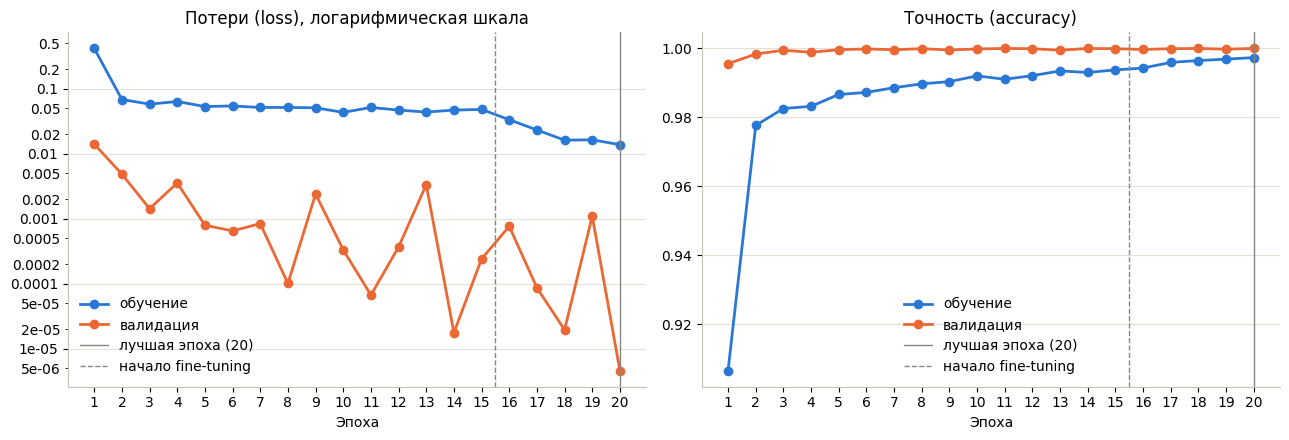

In [30]:
# Обучение классификатора (раздел 7) и fine-tuning на одной оси эпох.
# Fine-tuning начинается с весов лучшей эпохи раздела 7
metrics = ["loss", "accuracy", "val_loss", "val_accuracy"]
combined = {k: history.history[k] + ft_history.history[k] for k in metrics}
plot_history(combined, epochs_run + ft_best_epoch, finetune_from=epochs_run + 1)

In [31]:
# Оценка дообученной модели на той же тестовой выборке
ft_test_loss, ft_test_acc = ft_model.evaluate(test_ds, verbose=0)
y_pred_ft = ft_model.predict(test_ds, verbose=0).argmax(axis=1)

print(f"Тестовая точность:  {test_acc:.4f} → {ft_test_acc:.4f}")
print(f"Тестовые потери:    {test_loss:.4f} → {ft_test_loss:.4f}")
print(f"Ошибок на тесте:    {(y_pred != y_true).sum()} → {(y_pred_ft != y_true).sum()} из {len(y_true)}")

Тестовая точность:  0.9839 → 0.9918
Тестовые потери:    0.2279 → 0.0749
Ошибок на тесте:    366 → 187 из 22688


**Результаты fine-tuning.** 5 эпох заняли 657,5 с (11,0 мин) — 131,5 с на эпоху, на 10 % дольше эпохи раздела 7: добавились градиенты через три свёрточных слоя блока 5 (около 9 % вычислений сети). Ранняя остановка не сработала, и лучшей оказалась последняя, 5-я эпоха (`val_loss` = 4,6·10⁻⁶), так что дообучение можно было продолжить. Потери на обучении сошли с плато раздела 7: 0,048 → 0,014.

На тесте fine-tuning вдвое сократил число ошибок: 366 → 187, accuracy 98,39 → **99,18 %**, loss 0,228 → 0,075, macro F1 0,984 → 0,992. Сильнее всего исправились классы, которые VGG16 путала по окраске (раздел 8.1): Nectarine Flat (53 → 3 ошибки), Pear 2 (58 → 9), Mango Red (29 → 0), Pepper Orange (22 → 0), Nectarine (13 → 0), Eggplant (42 → 15). Зато появились ошибки в Carambula (0 → 17) и Pepino (0 → 13), а у Tomato Heart их стало больше (41 → 47): признаки блока 5 перестроились под Fruits-360, и часть границ между классами сместилась. Признаки ImageNet различают объекты, но не сорта похожих плодов, и дообучение верхнего блока подстраивает их под эту задачу.

### 12.2. Сравнение с CNN из работы № 9 (задание 9)

Чтобы сравнение было честным, CNN из работы № 9 скачивается из её репозитория (https://github.com/Danil20340/fruits-360) и оценивается на тех же 22 688 тестовых изображениях, а обе модели обучались на одном и том же разбиении `Training` (seed = 123). CNN принимает изображения 100×100, поэтому ей подаётся кэш тестовой выборки до ресайза (п. 5.6). Время обучения CNN взято из отчёта по работе № 9: 584 с на GPU T4 во float32.

In [32]:
import urllib.request

# CNN из лабораторной работы № 9 — по raw-ссылкам из её репозитория
CNN_REPO = "https://github.com/Danil20340/fruits-360/raw/main"
CNN_FILE = "lab9_fruits360_cnn_model.h5"
urllib.request.urlretrieve(f"{CNN_REPO}/fruits360_cnn_model.h5", CNN_FILE)
urllib.request.urlretrieve(f"{CNN_REPO}/class_names.txt", "lab9_class_names.txt")

cnn_model = tf.keras.models.load_model(CNN_FILE, compile=False)
with open("lab9_class_names.txt", encoding="utf-8") as f:
    assert [line.strip() for line in f if line.strip()] == class_names, "Порядок классов у моделей различается"

# CNN принимает изображения 100×100 — подаём кэш тестовой выборки до ресайза
start = time.time()
y_pred_cnn = cnn_model.predict(test_cached, verbose=0).argmax(axis=1)
cnn_predict_time = time.time() - start
print(f"CNN (работа № 9): accuracy {np.mean(y_pred_cnn == y_true):.4f}, ошибок {(y_pred_cnn != y_true).sum()}, "
      f"предсказание {cnn_predict_time:.1f} с ({len(y_true) / cnn_predict_time:.0f} изображений/с)")

CNN (работа № 9): accuracy 0.9917, ошибок 189, предсказание 5.0 с (4539 изображений/с)


In [33]:
def macro_f1(y_hat):
    return classification_report(y_true, y_hat, labels=all_labels, output_dict=True, zero_division=0)["macro avg"]["f1-score"]


def n_trainable(m):
    return sum(int(np.prod(w.shape)) for w in m.trainable_weights)


def epochs_label(n):
    """Число эпох с правильным окончанием: 1 эпоха, 3 эпохи, 5 эпох."""
    if n % 10 == 1 and n % 100 != 11:
        return f"{n} эпоха"
    if 2 <= n % 10 <= 4 and not 12 <= n % 100 <= 14:
        return f"{n} эпохи"
    return f"{n} эпох"


CNN_TRAINING_TIME, CNN_EPOCHS = 584.05, 17     # из отчёта по работе № 9 (GPU T4, float32)
n_test = len(y_true)

summary = pd.DataFrame({
    "CNN (работа № 9)": [
        "100×100",
        f"{cnn_model.count_params() / 1e6:.2f} / {n_trainable(cnn_model) / 1e6:.2f}",
        "≈ 0,15",
        f"{CNN_TRAINING_TIME:.0f} с, {epochs_label(CNN_EPOCHS)} (float32)",
        f"{np.mean(y_pred_cnn == y_true):.4f}",
        f"{macro_f1(y_pred_cnn):.4f}",
        f"{(y_pred_cnn != y_true).sum()}",
        f"{n_test / cnn_predict_time:.0f}",
        f"{os.path.getsize(CNN_FILE) / 2**20:.1f}",
    ],
    "VGG16, Transfer Learning": [
        f"{IMG_HEIGHT}×{IMG_WIDTH}",
        f"{model.count_params() / 1e6:.2f} / {n_trainable(model) / 1e6:.2f}",
        "≈ 15,3",
        f"{training_time:.0f} с, {epochs_label(epochs_run)} ({mixed_precision.global_policy().name})",
        f"{test_acc:.4f}",
        f"{macro_f1(y_pred):.4f}",
        f"{(y_pred != y_true).sum()}",
        f"{n_test / vgg_predict_time:.0f}",
        f"{os.path.getsize(MODEL_FILE) / 2**20:.1f}",
    ],
    "VGG16 + fine-tuning block5": [
        f"{IMG_HEIGHT}×{IMG_WIDTH}",
        f"{ft_model.count_params() / 1e6:.2f} / {n_trainable(ft_model) / 1e6:.2f}",
        "≈ 15,3",
        f"+{ft_time:.0f} с, {epochs_label(ft_epochs_run)} (итого {training_time + ft_time:.0f} с)",
        f"{ft_test_acc:.4f}",
        f"{macro_f1(y_pred_ft):.4f}",
        f"{(y_pred_ft != y_true).sum()}",
        "как у VGG16",
        "не сохранялась",
    ],
}, index=pd.Index([
    "Размер входа",
    "Параметров, млн (всего / обучаемых)",
    "Вычислений на изображение, млрд умножений-сложений",
    "Время обучения на GPU T4",
    "Accuracy на тесте",
    "Macro F1",
    f"Ошибок из {n_test}",
    "Скорость предсказания, изображений/с",
    "Файл модели, МБ",
], name="Показатель"))
summary

,CNN (работа № 9),"VGG16, Transfer Learning",VGG16 + fine-tuning block5
Показатель,,,
Размер входа,100×100,224×224,224×224
"Параметров, млн (всего / обучаемых)",5.18 / 5.18,15.04 / 0.33,15.04 / 7.41
"Вычислений на изображение, млрд умножений-сложений","≈ 0,15","≈ 15,3","≈ 15,3"
Время обучения на GPU T4,"584 с, 17 эпох (float32)","1786 с, 15 эпох (mixed_float16)","+657 с, 5 эпох (итого 2443 с)"
Accuracy на тесте,0.9917,0.9839,0.9918
Macro F1,0.9909,0.9841,0.9919
Ошибок из 22688,189,366,187
"Скорость предсказания, изображений/с",4539,577,как у VGG16
"Файл модели, МБ",19.8,62.5,не сохранялась


In [34]:
# Ошибки по классам: сколько тестовых изображений класса каждая модель отнесла к другому классу
model_cols = ["CNN (№ 9)", "VGG16", "VGG16 + FT"]
per_class_errors = pd.DataFrame({
    "Изображений": np.bincount(y_true, minlength=NUM_CLASSES),
    "CNN (№ 9)": np.bincount(y_true[y_pred_cnn != y_true], minlength=NUM_CLASSES),
    "VGG16": np.bincount(y_true[y_pred != y_true], minlength=NUM_CLASSES),
    "VGG16 + FT": np.bincount(y_true[y_pred_ft != y_true], minlength=NUM_CLASSES),
}, index=pd.Index(class_names, name="Класс"))

print("Классов, в которых есть ошибки:",
      ", ".join(f"{col} — {(per_class_errors[col] > 0).sum()}" for col in model_cols), f"(из {NUM_CLASSES})")

# Насколько пересекаются ошибки CNN и VGG16 (Transfer Learning)
cnn_wrong, vgg_wrong = y_pred_cnn != y_true, y_pred != y_true
print(f"Ошибается только CNN: {(cnn_wrong & ~vgg_wrong).sum()}, только VGG16: {(vgg_wrong & ~cnn_wrong).sum()}, "
      f"обе модели: {(cnn_wrong & vgg_wrong).sum()}")

# 20 классов с наибольшим суммарным числом ошибок трёх моделей
order = per_class_errors[model_cols].sum(axis=1).sort_values(ascending=False, kind="stable").index
per_class_errors.loc[order].head(20)

Классов, в которых есть ошибки: CNN (№ 9) — 8, VGG16 — 21, VGG16 + FT — 18 (из 131)
Ошибается только CNN: 100, только VGG16: 277, обе модели: 89


,Изображений,CNN (№ 9),VGG16,VGG16 + FT
Класс,,,,
Corn Husk,154,38,43,31
Tomato Heart,228,0,41,47
Nectarine Flat,160,29,53,3
Eggplant,156,16,42,15
Corn,150,63,6,0
Pear 2,232,0,58,9
Beetroot,150,28,19,17
Mango Red,142,0,29,0
Pepper Orange,234,0,22,0


**Что показывает сравнение.**
- **Качество.** CNN, обученная с нуля, точнее VGG16 с замороженной свёрточной частью: 99,17 % против 98,39 % (189 ошибок против 366). Только fine-tuning блока 5 выводит VGG16 на тот же уровень: 99,18 %, 187 ошибок, macro F1 0,992 против 0,991 у CNN. CNN на этом тесте дала ровно те же 99,17 % и 189 ошибок, что в работе № 9, — модель из репозитория воспроизводит результат.
- **Цена.** VGG16 выполняет в 100 раз больше вычислений на изображение, предсказывает в 7,9 раза медленнее (577 против 4539 изображений/с на T4), файл модели в 3,2 раза больше (62,5 против 19,8 МБ), а обучение вместе с fine-tuning заняло в 4,2 раза больше времени (2443 против 584 с) — несмотря на смешанную точность и почти в 16 раз меньшее число обучаемых параметров на первом этапе.
- **Разные ошибки.** CNN ошибается в 8 классах, VGG16 — в 21, но сами ошибки почти не пересекаются: из 466 тестовых изображений, на которых ошибается хотя бы одна модель, общих только 89. VGG16 почти полностью исправила главную проблему CNN — Corn (63 → 6 ошибок, после fine-tuning — 0) — и Pear Abate (11 → 0), но добавила свои: Pear 2, Tomato Heart, Mango Red, Pepper Orange. Трудными для обеих моделей остались Corn Husk, Nectarine Flat, Eggplant и Beetroot — плоды, снятые с торца или со стороны чашечки.
- **Почему перенос не дал выигрыша.** Fruits-360 — «лабораторный» датасет: один плод на белом фоне при одинаковом свете, и для классификации хватает цвета и силуэта, которые CNN за 17 эпох выучивает прямо на этих данных. Признаки ImageNet рассчитаны на разнообразные фотографии 1000 категорий объектов; тонкие различия сортов (Tomato Heart и Tomato 3, Pear 2 и Pear Forelle) они передают хуже, тем более что изображения 100×100 увеличены до 224×224 и выглядят размытыми. Сильные стороны Transfer Learning — быстрая сходимость (99,6 % на валидации уже после первой эпохи) и устойчивость к реальным фотографиям с другим фоном и светом — этим тестом почти не измеряются.

### 12.3. Выводы

**Что сделано.** Создан публичный репозиторий `fruits-360-vgg`. Датасет Fruits-360 (131 класс, 90 380 изображений) загружен по прямой ссылке, изображения увеличены до 224×224. Построены VGG16 «с нуля» (только для сравнения числа параметров) и основная модель — VGG16 с весами ImageNet, замороженной свёрточной частью и новым классификатором GAP → Dense(512) → Dropout(0,5) → Dense(131); предобработка VGG16 встроена в модель. Модель обучена со смешанной точностью, ранней остановкой и замером времени, оценена на тесте, сохранена в репозиторий и загружена обратно по raw-ссылкам — предсказания совпали полностью. Дополнительно визуализированы активации `block1_conv1` и `block5_conv3` и выполнен fine-tuning блока 5; модели сравнены с CNN из работы № 9 на одной и той же тестовой выборке.

**Итоги:**

| Показатель | VGG16, Transfer Learning | после fine-tuning block5 |
|---|---|---|
| Accuracy на тесте | **98,39 %** (366 ошибок из 22 688) | **99,18 %** (187 ошибок) |
| Macro F1 | 0,984 | 0,992 |
| Время обучения (GPU T4, mixed precision) | **1786 с (29,8 мин)**, 15 эпох | +657 с (11,0 мин), 5 эпох; всего 2443 с (40,7 мин) |
| Параметров (всего / обучаемых) | 15,04 млн / 0,33 млн | 15,04 млн / 7,41 млн |
| Файл модели | 62,5 МБ | не сохранялась |

Для сравнения, CNN из работы № 9: 99,17 % (189 ошибок), обучение 584 с, 5,18 млн параметров, файл 19,8 МБ.

**Выводы:**
1. Transfer Learning с замороженной VGG16 работает «из коробки»: 99,6 % на валидации уже после первой эпохи и 98,39 % на тесте, хотя обучаются только 2,2 % параметров. Но на этом датасете замороженных признаков ImageNet не хватает, чтобы догнать CNN, обученную с нуля: тонкие различия сортов они передают хуже (раздел 8.1).
2. Fine-tuning блока 5 вдвое уменьшил число ошибок и вывел VGG16 на уровень CNN (99,18 % против 99,17 %). Та же точность стоит в 4 раза больше времени обучения, в 8 раз более медленного инференса и в 3 раза большего файла. Для Fruits-360 VGG16 избыточна — это согласуется с выводом методических указаний: VGG хороша как учебная архитектура, а на практике лучше более лёгкие сети.
3. Ошибки CNN и VGG16 различаются (общих — 89 из 466), то есть модели опираются на разные признаки, и их можно объединить (п. 12.4).
4. Валидация на случайных 20 % кадров снова почти бесполезна: 99,9–100 % на валидации при 98,4 % на тесте. Сигнал для ранней остановки шумный: случайные новые минимумы `val_loss` появлялись чаще, чем раз в 5 эпох, и она не сработала ни при обучении, ни при fine-tuning.

**Трудности и как они решены:**
- В шаблоне методических указаний нет предобработки VGG16 (`preprocess_input`), а без неё веса ImageNet получают вход в другом формате. Предобработка встроена в модель; слой `Lambda` для этого не подошёл — в Keras 3 такая модель не загружается обратно, — поэтому `preprocess_input` обёрнут в мини-модель из стандартных операций.
- Кэш изображений 224×224 занял бы 12,7 ГБ — всю оперативную память Colab. Кэшируются исходные изображения 100×100 в `uint8` (2,5 ГБ), а ресайз выполняется на лету после кэша.
- VGG16 на входе 224×224 тяжела для обучения, поэтому на T4 включена смешанная точность (float16 на тензорных ядрах): эпоха заняла около 2 минут.
- `load_img` по умолчанию увеличивает изображение методом `nearest`, а при обучении использовался `bilinear`, поэтому в `predict_image` интерполяция указана явно.
- Файл модели (62,5 МБ) больше лимита загрузки через сайт GitHub (25 МБ), поэтому он загружен через `git push`.

### 12.4. Возможные улучшения

1. **Более долгий и глубокий fine-tuning.** Лучшей была последняя эпоха дообучения, так что его стоит продолжить (10–15 эпох) и разморозить ещё блок 4 с тем же маленьким шагом; шаг удобно снижать по расписанию (`ReduceLROnPlateau` или косинусное затухание).
2. **Аугментация данных** (`RandomRotation`, `RandomFlip`, `RandomZoom`, `RandomContrast`): обе модели ошибаются на редких ракурсах — торец, чашечка, донце, — и повороты с масштабированием добавят такие ракурсы в обучение.
3. **Кэширование признаков на первом этапе.** Пока свёрточная часть заморожена, её выход для каждого изображения не меняется, и все 15 эпох пересчитывают одно и то же. Если один раз сохранить векторы после GlobalAveragePooling (512 чисел на изображение, около 185 МБ для всех выборок), классификатор будет обучаться за секунды, а весь первый этап займёт несколько минут вместо 30. С аугментацией этот приём не совмещается.
4. **Ансамбль CNN и VGG16.** Ошибки моделей пересекаются только на 89 изображениях из 466, поэтому усреднение их вероятностей может исправить часть ошибок каждой модели.
5. **Честная валидация** — деление `Training` блоками кадров, а не случайно, как предлагалось в работе № 9: тогда ранняя остановка и выбор лучшей эпохи будут опираться на осмысленный сигнал.
6. **Меньшее разрешение или более лёгкая сеть.** Свёрточная часть VGG16 работает и на входе 100×100 или 128×128 — вычислений в 3–5 раз меньше, без увеличения размытых кадров. Ещё эффективнее современные сети (MobileNetV2, EfficientNetB0, ResNet50): при такой же или более высокой точности на ImageNet у них в 5–40 раз меньше параметров.
7. **Проверка на реальных фотографиях** (папка `test-multiple_fruits` из архива, снимки из интернета): именно там должны проявиться преимущества признаков ImageNet перед CNN, обученной только на белом фоне.

## 13. Список использованных источников

1. Simonyan K., Zisserman A. Very Deep Convolutional Networks for Large-Scale Image Recognition // ICLR. — 2015. — URL: https://arxiv.org/abs/1409.1556
2. Russakovsky O., Deng J., Su H. et al. ImageNet Large Scale Visual Recognition Challenge // International Journal of Computer Vision. — 2015. — Vol. 115, № 3. — P. 211–252.
3. Yosinski J., Clune J., Bengio Y., Lipson H. How transferable are features in deep neural networks? // Advances in Neural Information Processing Systems 27. — 2014. — P. 3320–3328.
4. Micikevicius P., Narang S., Alben J. et al. Mixed Precision Training // ICLR. — 2018. — URL: https://arxiv.org/abs/1710.03740
5. LeCun Y., Bottou L., Bengio Y., Haffner P. Gradient-based learning applied to document recognition // Proceedings of the IEEE. — 1998. — Vol. 86, № 11. — P. 2278–2324.
6. Krizhevsky A., Sutskever I., Hinton G. E. ImageNet Classification with Deep Convolutional Neural Networks // Advances in Neural Information Processing Systems 25. — 2012. — P. 1097–1105.
7. Szegedy C., Liu W., Jia Y. et al. Going Deeper with Convolutions // CVPR. — 2015. — P. 1–9.
8. He K., Zhang X., Ren S., Sun J. Deep Residual Learning for Image Recognition // CVPR. — 2016. — P. 770–778.
9. Howard A. G., Zhu M., Chen B. et al. MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications. — 2017. — URL: https://arxiv.org/abs/1704.04861
10. Tan M., Le Q. V. EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks // ICML. — 2019. — P. 6105–6114.
11. Lin M., Chen Q., Yan S. Network In Network // ICLR. — 2014. — URL: https://arxiv.org/abs/1312.4400
12. Kingma D. P., Ba J. Adam: A Method for Stochastic Optimization // ICLR. — 2015. — URL: https://arxiv.org/abs/1412.6980
13. Mureșan H., Oltean M. Fruit recognition from images using deep learning // Acta Universitatis Sapientiae, Informatica. — 2018. — Vol. 10, Issue 1. — P. 26–42.
14. Fruits-360: A dataset of images containing fruits and vegetables. — URL: https://github.com/Horea94/Fruit-Images-Dataset
15. Chollet F. Deep Learning with Python. — 2nd ed. — Manning, 2021. — Глава 8: предобученные модели, извлечение признаков и fine-tuning.
16. Документация Keras: VGG16 и VGG19, Transfer learning & fine-tuning, Mixed precision. — URL: https://keras.io/api/applications/vgg/, https://keras.io/guides/transfer_learning/, https://keras.io/api/mixed_precision/
17. NVIDIA T4 Tensor Core GPU: технические характеристики. — URL: https://www.nvidia.com/en-us/data-center/tesla-t4/
18. Бронников Д.С. Отчёт по лабораторной работе № 9 «Классификация изображений Fruits-360 с помощью CNN». — URL: https://github.com/Danil20340/fruits-360
19. Методические указания к заданию № 10 «Классификация изображений Fruits-360 с использованием сети VGG (VGG16 / VGG19)».

## 14. Приложение. Полный код с комментариями

Код всех ячеек ноутбука в порядке выполнения.

```python
# ===== 5.1. Импорт библиотек =====
# Импорт библиотек
import os
import time                      # замер времени обучения
import pathlib                   # работа с путями
import zipfile                   # распаковка архива с датасетом

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter, LogLocator
import tensorflow as tf
from tensorflow.keras import layers, models, mixed_precision
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix

# Воспроизводимость: один seed для Python, NumPy и TensorFlow
SEED = 123
tf.keras.utils.set_random_seed(SEED)

# Смешанная точность (раздел 3.6): на GPU вычисления идут во float16, веса хранятся во float32.
# На CPU float16 не ускоряет, а замедляет вычисления, поэтому там остаётся float32
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    mixed_precision.set_global_policy("mixed_float16")

# Оформление графиков, как в работе № 9: два цвета для пар серий (обучение / проверка)
# и одноцветная шкала для матриц и карт признаков
C_BLUE, C_ORANGE, C_MUTED = "#2a78d6", "#eb6834", "#898781"
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})

print(f"TensorFlow {tf.__version__}")
print("GPU:", gpus or "не найден — обучение пойдёт на CPU")
print("Политика вычислений:", mixed_precision.global_policy().name)


# ===== 5.2. Загрузка датасета =====
# Прямая ссылка на архив датасета (задание 1)
DATASET_URL = "https://github.com/Horea94/Fruit-Images-Dataset/archive/refs/heads/master.zip"

archive_path = pathlib.Path(tf.keras.utils.get_file("Fruit-Images-Dataset-master.zip", origin=DATASET_URL))
print(f"Архив: {archive_path} ({archive_path.stat().st_size / 2**20:.0f} МБ)")

# Распаковываем только Training и Test (один раз)
extract_root = archive_path.parent / "fruits-360"
data_dir = extract_root / "Fruit-Images-Dataset-master"
if not (data_dir / "Training").exists():
    prefixes = ("Fruit-Images-Dataset-master/Training/", "Fruit-Images-Dataset-master/Test/")
    with zipfile.ZipFile(archive_path) as zf:
        zf.extractall(extract_root, members=[m for m in zf.namelist() if m.startswith(prefixes)])

train_dir = data_dir / "Training"
test_dir = data_dir / "Test"
print(f"Папка обучения: {train_dir.exists()}")
print(f"Папка тестирования: {test_dir.exists()}")


# ===== 5.3. Создание наборов данных =====
BATCH_SIZE = 32
IMG_HEIGHT = 224                 # VGG16 обучалась на изображениях 224×224
IMG_WIDTH = 224
ORIG_SIZE = (100, 100)           # исходный размер изображений Fruits-360

# Обучающая выборка: 80 % папки Training
train_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=ORIG_SIZE,
    batch_size=BATCH_SIZE,
)

# Валидационная выборка: оставшиеся 20 % папки Training
val_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=ORIG_SIZE,
    batch_size=BATCH_SIZE,
)

# Тестовая выборка: папка Test, без перемешивания
test_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=ORIG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_raw.class_names
assert class_names == test_raw.class_names, "Классы в Training и Test не совпадают"
NUM_CLASSES = len(class_names)
print(f"\nКоличество классов: {NUM_CLASSES}")
print(f"Примеры классов: {class_names[:5]}")


def resize_to_vgg(images, labels):
    # Ресайз до 224×224 той же функцией и интерполяцией, что внутри image_dataset_from_directory
    return tf.image.resize(images, (IMG_HEIGHT, IMG_WIDTH), method="bilinear"), labels


images, labels = next(iter(train_raw.take(1).map(resize_to_vgg)))
print(f"Батч после ресайза: {tuple(images.shape)} — {images.shape[0]} изображений {IMG_HEIGHT}×{IMG_WIDTH}×3")


# ===== 5.4. Статистика датасета =====
# Число изображений в каждой папке-классе
def count_images(directory):
    return pd.Series({d.name: len(list(d.glob("*.jpg"))) for d in sorted(directory.iterdir()) if d.is_dir()})


counts = pd.DataFrame({"Training": count_images(train_dir), "Test": count_images(test_dir)})
counts.index.name = "Класс"

sample_img = tf.keras.utils.load_img(next(train_dir.glob("*/*.jpg")))
print(f"Классов: {len(counts)}")
print(f"Изображений: Training — {counts['Training'].sum()}, Test — {counts['Test'].sum()}, всего — {counts.values.sum()}")
print(f"Разбиение Training: обучение — {len(train_raw.file_paths)}, валидация — {len(val_raw.file_paths)}")
print(f"Исходный размер изображения: {sample_img.size[0]}×{sample_img.size[1]}, режим {sample_img.mode}; "
      f"на входе VGG16 — {IMG_WIDTH}×{IMG_HEIGHT}")

# Сводная статистика по числу изображений в классе
counts.describe().round(1)


# ===== 5.5. Визуализация примеров =====
# Первые 9 изображений из обучающей выборки после ресайза до 224×224
plt.figure(figsize=(9, 9.4))
for images, labels in train_raw.take(1).map(resize_to_vgg):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]], fontsize=10)
        plt.axis("off")
plt.suptitle(f"Изображения обучающей выборки после ресайза до {IMG_HEIGHT}×{IMG_WIDTH}")
plt.tight_layout()
plt.show()


# ===== 5.6. Оптимизация конвейера данных =====
AUTOTUNE = tf.data.AUTOTUNE


def to_uint8(images, labels):
    # Пиксели — целые 0..255, поэтому переход к uint8 без потерь, а кэш в 4 раза меньше
    return tf.cast(images, tf.uint8), labels


# Кэш хранит изображения 100×100 в uint8; ресайз до 224×224 выполняется после кэша, на лету.
# shuffle стоит до ресайза: буфер из 1000 батчей 224×224 во float32 занял бы около 18 ГБ
train_cached = train_raw.map(to_uint8, num_parallel_calls=AUTOTUNE).cache()
val_cached = val_raw.map(to_uint8, num_parallel_calls=AUTOTUNE).cache()
test_cached = test_raw.map(to_uint8, num_parallel_calls=AUTOTUNE).cache()

train_ds = train_cached.shuffle(1000, seed=SEED).map(resize_to_vgg, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_cached.map(resize_to_vgg, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_cached.map(resize_to_vgg, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Объём кэша всех трёх выборок в разных вариантах хранения
n_images = len(train_raw.file_paths) + len(val_raw.file_paths) + len(test_raw.file_paths)
for title, side, bytes_per_value in [("100×100, uint8 (используется)", 100, 1),
                                     ("224×224, uint8", 224, 1),
                                     ("224×224, float32", 224, 4)]:
    print(f"Кэш {title}: {n_images * side * side * 3 * bytes_per_value / 2**30:.1f} ГБ")


# ===== 6.1. VGG16 «с нуля» =====
# Шаг 7a методических указаний: архитектура VGG16 без предобученных весов (weights=None)
# и классификатор Flatten → Dense(512) → Dropout(0.5) → Dense(131).
# Модель только строится и не обучается (см. текст ниже)
base_scratch = VGG16(include_top=False, weights=None, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))

model_scratch = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    base_scratch,
    layers.Flatten(),                          # 7×7×512 → 25 088
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32"),
], name="vgg16_scratch")

model_scratch.summary()

# Модель дальше не нужна — освобождаем память
del model_scratch, base_scratch


# ===== 6.2. VGG16 с Transfer Learning =====
# Свёрточная часть VGG16 с весами ImageNet, без классификатора на 1000 классов
base_vgg = VGG16(include_top=False, weights="imagenet", input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
base_vgg.trainable = False       # замораживаем все 13 свёрточных слоёв

# Предобработка VGG16 как часть модели: RGB → BGR и вычитание среднего пикселя ImageNet (раздел 3.4)
pre_input = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
vgg_preprocess = models.Model(pre_input, preprocess_input(pre_input), name="vgg16_preprocess")

model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),   # изображение RGB, значения 0..255
    vgg_preprocess,                                   # вход в формате, на котором обучалась VGG16
    base_vgg,                                         # замороженный экстрактор признаков: → 7×7×512
    layers.GlobalAveragePooling2D(),                  # 7×7×512 → 512 (раздел 3.5)
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32"),  # softmax во float32 (раздел 3.6)
], name="fruits360_vgg16")

# Вывод архитектуры
model.summary()


# ===== 6.2. Проверка предобработки =====
# Каналы переставлены (RGB → BGR) и сдвинуты на средние ImageNet; результат совпадает с preprocess_input
sample, _ = next(iter(train_raw.take(1).map(resize_to_vgg)))
processed = vgg_preprocess(sample).numpy()
print("Средние по каналам до предобработки    (R, G, B):", np.round(sample.numpy().mean(axis=(0, 1, 2)), 1))
print("Средние по каналам после предобработки (B, G, R):", np.round(processed.mean(axis=(0, 1, 2)), 1))
print("Совпадает с preprocess_input:", np.allclose(processed, preprocess_input(sample.numpy().copy())))


# ===== 6.3. Активации block1_conv1 и block5_conv3 =====
# Модель для чтения промежуточных выходов VGG16: первый и последний свёрточные слои
activation_model = models.Model(
    base_vgg.input,
    [base_vgg.get_layer("block1_conv1").output, base_vgg.get_layer("block5_conv3").output],
)

# Тестовое изображение, увеличенное до 224×224 так же, как в predict_image (раздел 9)
act_path = test_dir / "Strawberry" / "321_100.jpg"
act_image = tf.keras.utils.img_to_array(
    tf.keras.utils.load_img(act_path, target_size=(IMG_HEIGHT, IMG_WIDTH), interpolation="bilinear"))
act1, act5 = [np.asarray(a[0], dtype="float32") for a in activation_model(vgg_preprocess(act_image[None, ...]))]


def show_activations(act, layer_name, n=16):
    """Показывает n каналов слоя с наибольшей средней активацией на изображении."""
    top = np.argsort(act.mean(axis=(0, 1)))[::-1][:n]
    fig, axes = plt.subplots(2, n // 2, figsize=(16, 5.2))
    for ax, ch in zip(axes.flat, top):
        ax.imshow(act[:, :, ch], cmap=SEQ_CMAP)
        ax.set_title(f"канал {ch}", fontsize=9)
        ax.axis("off")
    silent = (act.max(axis=(0, 1)) == 0).mean()
    fig.suptitle(f"{layer_name}: {act.shape[2]} карт {act.shape[0]}×{act.shape[1]}, показаны 16 самых активных; "
                 f"каналов без отклика на этом изображении — {silent:.0%}, нулевых значений — {(act == 0).mean():.0%}")
    plt.tight_layout()
    plt.show()


# Исходное изображение и средняя по 512 каналам активация block5_conv3
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.9))
axes[0].imshow(act_image.astype("uint8"))
axes[0].set_title(f"Вход: {act_path.parent.name}/{act_path.name}", fontsize=10)
axes[1].imshow(act5.mean(axis=2), cmap=SEQ_CMAP)
axes[1].set_title("block5_conv3: среднее по 512 каналам", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

show_activations(act1, "block1_conv1")
show_activations(act5, "block5_conv3")


# ===== 7. Компиляция модели =====
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),  # при mixed_float16 Keras добавит масштабирование потерь
    loss="sparse_categorical_crossentropy",                  # метки — целые номера классов
    metrics=["accuracy"],
)
print("Оптимизатор:", type(model.optimizer).__name__)


# ===== 7. Обучение модели с фиксацией времени =====
EPOCHS = 15

# Ранняя остановка, чтобы избежать переобучения
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

# Замер времени обучения (обязательное требование)
print("Начало обучения...")
start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop],
    verbose=1,
)

end_time = time.time()
training_time = end_time - start_time

epochs_run = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nОбучение завершено за {training_time:.2f} секунд ({training_time / 60:.2f} минут)")
print(f"Эпох выполнено: {epochs_run} из {EPOCHS}, в среднем {training_time / epochs_run:.1f} с на эпоху")
print(f"Лучшая эпоха по val_loss: {best_epoch}")


# ===== 7. Графики потерь и точности =====
def plot_history(hist, best_epoch, finetune_from=None):
    """Графики потерь (логарифмическая шкала) и точности на обучающей и валидационной выборках."""
    epochs_range = np.arange(1, len(hist["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    panels = [("loss", "Потери (loss), логарифмическая шкала"), ("accuracy", "Точность (accuracy)")]

    for ax, (metric, title) in zip(axes, panels):
        ax.plot(epochs_range, hist[metric], color=C_BLUE, lw=2, marker="o", ms=6, label="обучение")
        ax.plot(epochs_range, hist[f"val_{metric}"], color=C_ORANGE, lw=2, marker="o", ms=6, label="валидация")
        ax.axvline(best_epoch, color=C_MUTED, lw=1, label=f"лучшая эпоха ({best_epoch})")
        if finetune_from is not None:
            ax.axvline(finetune_from - 0.5, color=C_MUTED, lw=1, ls="--", label="начало fine-tuning")
        ax.set(title=title, xlabel="Эпоха", xticks=epochs_range)
        ax.grid(axis="y")
        ax.legend()

    # Логарифмическая шкала потерь с обычными подписями: 0.01, 0.02, 0.05, 0.1, ...
    plain = FuncFormatter(lambda v, _: f"{v:g}")
    axes[0].set_yscale("log")
    axes[0].yaxis.set_major_formatter(plain)
    axes[0].yaxis.set_minor_locator(LogLocator(subs=(2, 5)))
    axes[0].yaxis.set_minor_formatter(plain)
    plt.tight_layout()
    plt.show()


plot_history(history.history, best_epoch)


# ===== 8. Оценка на тестовой выборке =====
# Оценка на тестовом наборе
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Тестовая точность (accuracy): {test_acc:.4f}")
print(f"Тестовые потери (loss): {test_loss:.4f}")


# ===== 8. Classification report =====
# Истинные метки и предсказания (тестовая выборка не перемешивается, поэтому порядок совпадает)
y_true = np.concatenate([labels.numpy() for _, labels in test_cached])
start = time.time()
vgg_probs = model.predict(test_ds, verbose=0)
vgg_predict_time = time.time() - start
y_pred = vgg_probs.argmax(axis=1)
all_labels = np.arange(NUM_CLASSES)

print(f"Предсказание для {len(y_true)} изображений: {vgg_predict_time:.1f} с "
      f"({len(y_true) / vgg_predict_time:.0f} изображений/с)\n")
print(classification_report(y_true, y_pred, labels=all_labels, target_names=class_names, digits=3, zero_division=0))


# ===== 8. Классы с наименьшим F1 =====
# 10 классов с наименьшим F1-score
report = classification_report(y_true, y_pred, labels=all_labels, target_names=class_names,
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[class_names, ["precision", "recall", "f1-score", "support"]]
per_class["support"] = per_class["support"].astype(int)
per_class.sort_values("f1-score").head(10).round(3)


# ===== 8. Матрица ошибок =====
# Полная матрица ошибок 131×131. Шкала цвета логарифмическая, иначе редкие ошибки
# не видны рядом с диагональю; нулевые клетки не закрашены
cm = confusion_matrix(y_true, y_pred, labels=all_labels)

fig, ax = plt.subplots(figsize=(11, 9.5))
sns.heatmap(cm, mask=(cm == 0), cmap=SEQ_CMAP, norm=LogNorm(vmin=1, vmax=cm.max()), square=True,
            xticklabels=10, yticklabels=10, cbar_kws={"label": "Число изображений (логарифмическая шкала)"}, ax=ax)
ax.set(title="Матрица ошибок на тестовой выборке (пустые клетки — нули)",
       xlabel="Предсказанный класс (номер)", ylabel="Истинный класс (номер)")
plt.show()


# ===== 8. Самые частые ошибки =====
# Самые частые ошибки — наибольшие внедиагональные элементы матрицы ошибок
errors = cm.copy()
np.fill_diagonal(errors, 0)
print(f"Ошибок на тесте: {errors.sum()} из {cm.sum()} ({errors.sum() / cm.sum():.2%})")

true_idx, pred_idx = np.nonzero(errors)
top = np.argsort(-errors[true_idx, pred_idx], kind="stable")[:10]
top_true, top_pred = true_idx[top], pred_idx[top]

top_pairs = pd.DataFrame({
    "Истинный класс": [class_names[i] for i in top_true],
    "Предсказанный класс": [class_names[j] for j in top_pred],
    "Ошибок": errors[top_true, top_pred],
    "% изображений класса": (100 * errors[top_true, top_pred] / cm[top_true].sum(axis=1)).round(1),
})
top_pairs


# ===== 8. Фрагмент матрицы ошибок =====
# Увеличенный фрагмент матрицы ошибок: только классы из 10 самых частых путаниц
focus = sorted(set(top_true) | set(top_pred))
sub_cm = cm[np.ix_(focus, focus)]
focus_names = [class_names[i] for i in focus]

fig, ax = plt.subplots(figsize=(1.5 + 0.6 * len(focus), 1 + 0.55 * len(focus)))
sns.heatmap(sub_cm, mask=(sub_cm == 0), annot=True, fmt="d", cmap=SEQ_CMAP, norm=LogNorm(vmin=1, vmax=cm.max()),
            square=True, cbar=False, xticklabels=focus_names, yticklabels=focus_names, ax=ax)
ax.set(title="Классы, которые путаются чаще всего (на диагонали — верные ответы)",
       xlabel="Предсказанный класс", ylabel="Истинный класс")
plt.show()


# ===== 8. Примеры ошибок =====
# По одному ошибочно классифицированному изображению для 8 самых частых пар «истинный → предсказанный»
test_files = np.array(test_raw.file_paths)
pairs = list(zip(top_true, top_pred))[:8]

fig, axes = plt.subplots(1, len(pairs), figsize=(2.2 * len(pairs), 3.5), squeeze=False)
for ax, (t, p) in zip(axes[0], pairs):
    idx = np.flatnonzero((y_true == t) & (y_pred == p))[0]
    ax.imshow(tf.keras.utils.load_img(test_files[idx]))
    ax.set_title(f"{class_names[t]}\n→ {class_names[p]} ({vgg_probs[idx, p]:.0%})\n{os.path.basename(test_files[idx])}",
                 fontsize=8)
    ax.axis("off")
fig.suptitle("Примеры ошибок: истинный класс → предсказанный (уверенность), имя файла")
plt.tight_layout()
plt.show()


# ===== 9. Функция predict_image =====
def predict_image(img_path):
    """
    Загружает изображение, подготавливает его и возвращает предсказанный класс и уверенность.
    """
    # Билинейная интерполяция, как в image_dataset_from_directory (у load_img по умолчанию — nearest)
    img = tf.keras.utils.load_img(img_path, target_size=(IMG_HEIGHT, IMG_WIDTH), interpolation="bilinear")
    img_array = tf.keras.utils.img_to_array(img)   # массив 224×224×3, значения 0..255
    img_array = tf.expand_dims(img_array, 0)       # добавляем размерность батча
    predictions = model.predict(img_array, verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = float(np.max(predictions[0]))
    return predicted_class, confidence


# ===== 9. Проверка на 5 изображениях =====
# 5 случайных изображений разных классов из тестовой выборки (seed фиксирован — набор воспроизводим)
rng = np.random.default_rng(SEED)
sample_paths = []
for cls in rng.choice(class_names, size=5, replace=False):
    files = sorted((test_dir / cls).glob("*.jpg"))
    sample_paths.append(files[rng.integers(len(files))])

# Номер файла в тестовой выборке — чтобы сравнить с предсказаниями раздела 8
file_index = {os.path.normpath(p): i for i, p in enumerate(test_raw.file_paths)}

rows = []
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, path in zip(axes, sample_paths):
    predicted, conf = predict_image(path)
    true_class = path.parent.name
    rows.append({"Файл": f"{true_class}/{path.name}", "Истинный класс": true_class,
                 "Предсказанный класс": predicted, "Уверенность": conf,
                 "Прогноз в разделе 8": class_names[y_pred[file_index[os.path.normpath(path)]]]})
    ax.imshow(tf.keras.utils.load_img(path))
    ax.set_title(f"Истинный: {true_class}\nПрогноз: {predicted} ({conf:.1%})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

task6_results = pd.DataFrame(rows)
task6_results


# ===== 10. Сохранение модели и списка классов =====
MODEL_FILE = "fruits360_vgg16_model.keras"
CLASSES_FILE = "class_names_vgg.txt"

# Сохраняем модель в формате .keras (архитектура, веса и состояние оптимизатора в одном файле)
model.save(MODEL_FILE)
print(f"Модель сохранена в {MODEL_FILE}")

# Сохраняем список классов в текстовый файл
with open(CLASSES_FILE, "w", encoding="utf-8") as f:
    for name in class_names:
        f.write(name + "\n")
print(f"Список классов сохранён в {CLASSES_FILE}")

for name in (MODEL_FILE, CLASSES_FILE):
    print(f"  {name}: {os.path.getsize(name) / 2**20:.2f} МБ")


# ===== 10. Скачивание файлов из Colab =====
# В Colab скачиваем файлы на компьютер, чтобы загрузить их в репозиторий
try:
    from google.colab import files
    files.download(MODEL_FILE)
    files.download(CLASSES_FILE)
except ImportError:
    print(f"Ноутбук запущен не в Colab: файлы лежат в папке {os.getcwd()}")


# ===== 11. Загрузка модели из репозитория =====
import urllib.request

import numpy as np
import tensorflow as tf

# Raw-ссылки на файлы в репозитории
url_model = "https://github.com/Danil20340/fruits-360-vgg/raw/main/fruits360_vgg16_model.keras"
url_classes = "https://github.com/Danil20340/fruits-360-vgg/raw/main/class_names_vgg.txt"

# Скачивание файлов (аналог !wget -O)
urllib.request.urlretrieve(url_model, "repo_fruits360_vgg16_model.keras")
urllib.request.urlretrieve(url_classes, "repo_class_names_vgg.txt")

# Загрузка модели; compile=False — модель нужна только для предсказаний
loaded_model = tf.keras.models.load_model("repo_fruits360_vgg16_model.keras", compile=False)

# Загрузка списка классов
with open("repo_class_names_vgg.txt", encoding="utf-8") as f:
    loaded_class_names = [line.strip() for line in f if line.strip()]

print(f"Модель загружена. Параметров: {loaded_model.count_params()}, классов: {len(loaded_class_names)}")


# Функция предсказания с загруженной моделью
def predict_loaded_image(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224), interpolation="bilinear")
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)
    predictions = loaded_model.predict(img_array, verbose=0)
    predicted_class = loaded_class_names[np.argmax(predictions[0])]
    confidence = float(np.max(predictions[0]))
    return predicted_class, confidence


# ===== 11. Сравнение с результатами задания 6 =====
# Предсказания загруженной модели для тех же изображений, что и в задании 6
loaded_results = [predict_loaded_image(path) for path in sample_paths]

comparison = task6_results[["Файл", "Предсказанный класс", "Уверенность"]].copy()
comparison["Класс (модель из репозитория)"] = [cls for cls, _ in loaded_results]
comparison["Уверенность (модель из репозитория)"] = [conf for _, conf in loaded_results]
comparison["Совпадает"] = (
    (comparison["Предсказанный класс"] == comparison["Класс (модель из репозитория)"])
    & np.isclose(comparison["Уверенность"], comparison["Уверенность (модель из репозитория)"], atol=1e-5)
)
display(comparison)

# Дополнительная проверка: полные векторы вероятностей обеих моделей на первом тестовом батче
batch_images, _ = next(iter(test_ds))
max_diff = np.abs(model.predict(batch_images, verbose=0) - loaded_model.predict(batch_images, verbose=0)).max()
print(f"Максимальное расхождение вероятностей на батче из {len(batch_images)} изображений: {max_diff:.1e}")
print("Результаты совпадают" if comparison["Совпадает"].all() and max_diff < 1e-5 else "ВНИМАНИЕ: результаты различаются")


# ===== 12.1. Подготовка fine-tuning =====
# Копия обученной модели: модель Transfer Learning из раздела 10 остаётся без изменений
ft_model = models.clone_model(model)
ft_model.set_weights(model.get_weights())

# Размораживаем только последний свёрточный блок VGG16 (block5_conv1–block5_conv3)
ft_base = ft_model.get_layer("vgg16")
ft_base.trainable = True
for layer in ft_base.layers:
    layer.trainable = layer.name.startswith("block5")

# После изменения trainable модель компилируется заново; шаг в 100 раз меньше, чем в разделе 7
ft_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

ft_trainable = sum(int(np.prod(w.shape)) for w in ft_model.trainable_weights)
print("Размороженные слои VGG16:", [layer.name for layer in ft_base.layers if layer.trainable and layer.weights])
print(f"Обучаемых параметров: {ft_trainable:,} из {ft_model.count_params():,} ({ft_trainable / ft_model.count_params():.1%})")


# ===== 12.1. Fine-tuning с фиксацией времени =====
FT_EPOCHS = 5

ft_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

# Замер времени fine-tuning
print("Начало fine-tuning...")
start_time = time.time()

ft_history = ft_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FT_EPOCHS,
    callbacks=[ft_early_stop],
    verbose=1,
)

ft_time = time.time() - start_time
ft_epochs_run = len(ft_history.history["loss"])
ft_best_epoch = int(np.argmin(ft_history.history["val_loss"])) + 1
print(f"\nFine-tuning завершён за {ft_time:.2f} секунд ({ft_time / 60:.2f} минут)")
print(f"Эпох выполнено: {ft_epochs_run} из {FT_EPOCHS}, в среднем {ft_time / ft_epochs_run:.1f} с на эпоху; "
      f"лучшая эпоха: {ft_best_epoch}")
print(f"Всего на обучение (классификатор + fine-tuning): {training_time + ft_time:.0f} с "
      f"({(training_time + ft_time) / 60:.1f} мин)")


# ===== 12.1. Графики обучения с fine-tuning =====
# Обучение классификатора (раздел 7) и fine-tuning на одной оси эпох.
# Fine-tuning начинается с весов лучшей эпохи раздела 7
metrics = ["loss", "accuracy", "val_loss", "val_accuracy"]
combined = {k: history.history[k] + ft_history.history[k] for k in metrics}
plot_history(combined, epochs_run + ft_best_epoch, finetune_from=epochs_run + 1)


# ===== 12.1. Качество после fine-tuning =====
# Оценка дообученной модели на той же тестовой выборке
ft_test_loss, ft_test_acc = ft_model.evaluate(test_ds, verbose=0)
y_pred_ft = ft_model.predict(test_ds, verbose=0).argmax(axis=1)

print(f"Тестовая точность:  {test_acc:.4f} → {ft_test_acc:.4f}")
print(f"Тестовые потери:    {test_loss:.4f} → {ft_test_loss:.4f}")
print(f"Ошибок на тесте:    {(y_pred != y_true).sum()} → {(y_pred_ft != y_true).sum()} из {len(y_true)}")


# ===== 12.2. CNN из работы № 9 =====
import urllib.request

# CNN из лабораторной работы № 9 — по raw-ссылкам из её репозитория
CNN_REPO = "https://github.com/Danil20340/fruits-360/raw/main"
CNN_FILE = "lab9_fruits360_cnn_model.h5"
urllib.request.urlretrieve(f"{CNN_REPO}/fruits360_cnn_model.h5", CNN_FILE)
urllib.request.urlretrieve(f"{CNN_REPO}/class_names.txt", "lab9_class_names.txt")

cnn_model = tf.keras.models.load_model(CNN_FILE, compile=False)
with open("lab9_class_names.txt", encoding="utf-8") as f:
    assert [line.strip() for line in f if line.strip()] == class_names, "Порядок классов у моделей различается"

# CNN принимает изображения 100×100 — подаём кэш тестовой выборки до ресайза
start = time.time()
y_pred_cnn = cnn_model.predict(test_cached, verbose=0).argmax(axis=1)
cnn_predict_time = time.time() - start
print(f"CNN (работа № 9): accuracy {np.mean(y_pred_cnn == y_true):.4f}, ошибок {(y_pred_cnn != y_true).sum()}, "
      f"предсказание {cnn_predict_time:.1f} с ({len(y_true) / cnn_predict_time:.0f} изображений/с)")


# ===== 12.2. Сводное сравнение моделей =====
def macro_f1(y_hat):
    return classification_report(y_true, y_hat, labels=all_labels, output_dict=True, zero_division=0)["macro avg"]["f1-score"]


def n_trainable(m):
    return sum(int(np.prod(w.shape)) for w in m.trainable_weights)


def epochs_label(n):
    """Число эпох с правильным окончанием: 1 эпоха, 3 эпохи, 5 эпох."""
    if n % 10 == 1 and n % 100 != 11:
        return f"{n} эпоха"
    if 2 <= n % 10 <= 4 and not 12 <= n % 100 <= 14:
        return f"{n} эпохи"
    return f"{n} эпох"


CNN_TRAINING_TIME, CNN_EPOCHS = 584.05, 17     # из отчёта по работе № 9 (GPU T4, float32)
n_test = len(y_true)

summary = pd.DataFrame({
    "CNN (работа № 9)": [
        "100×100",
        f"{cnn_model.count_params() / 1e6:.2f} / {n_trainable(cnn_model) / 1e6:.2f}",
        "≈ 0,15",
        f"{CNN_TRAINING_TIME:.0f} с, {epochs_label(CNN_EPOCHS)} (float32)",
        f"{np.mean(y_pred_cnn == y_true):.4f}",
        f"{macro_f1(y_pred_cnn):.4f}",
        f"{(y_pred_cnn != y_true).sum()}",
        f"{n_test / cnn_predict_time:.0f}",
        f"{os.path.getsize(CNN_FILE) / 2**20:.1f}",
    ],
    "VGG16, Transfer Learning": [
        f"{IMG_HEIGHT}×{IMG_WIDTH}",
        f"{model.count_params() / 1e6:.2f} / {n_trainable(model) / 1e6:.2f}",
        "≈ 15,3",
        f"{training_time:.0f} с, {epochs_label(epochs_run)} ({mixed_precision.global_policy().name})",
        f"{test_acc:.4f}",
        f"{macro_f1(y_pred):.4f}",
        f"{(y_pred != y_true).sum()}",
        f"{n_test / vgg_predict_time:.0f}",
        f"{os.path.getsize(MODEL_FILE) / 2**20:.1f}",
    ],
    "VGG16 + fine-tuning block5": [
        f"{IMG_HEIGHT}×{IMG_WIDTH}",
        f"{ft_model.count_params() / 1e6:.2f} / {n_trainable(ft_model) / 1e6:.2f}",
        "≈ 15,3",
        f"+{ft_time:.0f} с, {epochs_label(ft_epochs_run)} (итого {training_time + ft_time:.0f} с)",
        f"{ft_test_acc:.4f}",
        f"{macro_f1(y_pred_ft):.4f}",
        f"{(y_pred_ft != y_true).sum()}",
        "как у VGG16",
        "не сохранялась",
    ],
}, index=pd.Index([
    "Размер входа",
    "Параметров, млн (всего / обучаемых)",
    "Вычислений на изображение, млрд умножений-сложений",
    "Время обучения на GPU T4",
    "Accuracy на тесте",
    "Macro F1",
    f"Ошибок из {n_test}",
    "Скорость предсказания, изображений/с",
    "Файл модели, МБ",
], name="Показатель"))
summary


# ===== 12.2. Ошибки по классам =====
# Ошибки по классам: сколько тестовых изображений класса каждая модель отнесла к другому классу
model_cols = ["CNN (№ 9)", "VGG16", "VGG16 + FT"]
per_class_errors = pd.DataFrame({
    "Изображений": np.bincount(y_true, minlength=NUM_CLASSES),
    "CNN (№ 9)": np.bincount(y_true[y_pred_cnn != y_true], minlength=NUM_CLASSES),
    "VGG16": np.bincount(y_true[y_pred != y_true], minlength=NUM_CLASSES),
    "VGG16 + FT": np.bincount(y_true[y_pred_ft != y_true], minlength=NUM_CLASSES),
}, index=pd.Index(class_names, name="Класс"))

print("Классов, в которых есть ошибки:",
      ", ".join(f"{col} — {(per_class_errors[col] > 0).sum()}" for col in model_cols), f"(из {NUM_CLASSES})")

# Насколько пересекаются ошибки CNN и VGG16 (Transfer Learning)
cnn_wrong, vgg_wrong = y_pred_cnn != y_true, y_pred != y_true
print(f"Ошибается только CNN: {(cnn_wrong & ~vgg_wrong).sum()}, только VGG16: {(vgg_wrong & ~cnn_wrong).sum()}, "
      f"обе модели: {(cnn_wrong & vgg_wrong).sum()}")

# 20 классов с наибольшим суммарным числом ошибок трёх моделей
order = per_class_errors[model_cols].sum(axis=1).sort_values(ascending=False, kind="stable").index
per_class_errors.loc[order].head(20)
```